<a href="https://colab.research.google.com/github/Nss2k23/ML_ES_678_Project/blob/main/MLCourseProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Online Shoppers Purchase Prediction

**Research question:** How do feature importance and classification thresholds affect performance
in identifying purchasing sessions while controlling false positives?

| Item | Definition |
|---|---|
| **Unit (one row)** | One browsing session on an online shop (12,330 sessions, one year) |
| **Target** | `Revenue`: 1 = the session ended in a purchase, 0 = no purchase (15.5% purchases) |
| **When the prediction is made** | The dataset only contains **end-of-session totals**, so the model classifies **completed sessions**. The intended use (flagging likely buyers during a visit) cannot be tested with this data. |
| **Information available then** | Date and visitor/technical features are known at the **start** of a session; page counts, durations and exit/bounce rates grow **during** it; **PageValues** is computed from purchases and has the highest **leakage risk**. We test how much the results depend on it (Sections 7.3, 8.2, 9.4). |
| **Scope of the claim** | Results hold for this shop and year; real-time (mid-session) prediction is not tested (see 9.4–9.5) |

**Approach:** majority-class baseline, Logistic Regression and Random Forest, tuned with 5-fold CV on a stratified 60/20/20 split,
scored by PR-AUC; threshold chosen on validation; test set used once.
**Depth component (graduate):** feature-group ablation (31 combinations), PageValues sensitivity and leakage audit, bootstrap confidence intervals and error analysis.

## 1. Load Data
Dataset: UCI Online Shoppers Purchasing Intention Dataset. Each row is one browsing session (12,330 sessions, 18 columns).

In [ ]:
import zipfile, glob

# TODO: unzip the uploaded file
zip_path = glob.glob("online*.zip")[0]
with zipfile.ZipFile(zip_path) as z:
    z.extractall(".")

# TODO: load the CSV
import pandas as pd
df = pd.read_csv("online_shoppers_intention.csv")

# TODO: sanity check shape and first rows
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 1.1 Initial Exploration
Check data types, missing values, class balance and duplicate rows.

In [ ]:
# TODO: check dtypes and missing values
print(df.dtypes)
print("missing:", df.isna().sum().sum())

# TODO: check class balance of the target
print(df["Revenue"].value_counts())
print(df["Revenue"].value_counts(normalize=True))

# TODO: check duplicate rows
print("duplicates:", df.duplicated().sum())

# TODO: summary stats for numeric columns
df.describe().T

# TODO: check categorical columns
for c in ["Month", "VisitorType", "Weekend"]:
    print(df[c].value_counts(), "\n")

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object
missing: 0
Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    0.845255
True     0.154745
Name: proportion, dtype: float64
duplicates: 125
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64 

VisitorType
Returning_Vi

## 1.2 Export to Excel (for manual inspection)
Raw data exported with duplicate rows flagged. This is for viewing only and does not change `df`.

In [ ]:
# import pandas as pd

# # TODO: load the raw data (before dedupe, so the Excel matches the original)
# raw = pd.read_csv("online_shoppers_intention.csv")

# # TODO: flag duplicate rows so you can filter them in Excel
# raw["is_duplicate"] = raw.duplicated()

# # TODO: export to Excel with a frozen header row and filters
# with pd.ExcelWriter("online_shoppers_data.xlsx", engine="openpyxl") as writer:
#     raw.to_excel(writer, sheet_name="Data", index=False)
#     ws = writer.sheets["Data"]
#     ws.freeze_panes = "A2"
#     ws.auto_filter.ref = ws.dimensions

# # TODO: download it to your computer
# from google.colab import files
# files.download("online_shoppers_data.xlsx")

### 1.3 Focused plots
Three plots that matter for the research question:
1. **Class balance:** how rare buyers are; this decides the metric (PR-AUC) and the need for class weighting.
2. **Buy rate by month:** whether the time of year matters (and which months are missing).
3. **PageValues for buyers vs non-buyers:** a first look at the feature we expect to be most important.

Month,Feb,Mar,May,June,Jul,Aug,Sep,Oct,Nov,Dec
sessions,184.000,1907.000,3364.000,288.000,432.000,433.000,448.000,549.000,2998.000,1727.000
buy_rate,0.016,0.101,0.109,0.101,0.153,0.176,0.192,0.209,0.254,0.125


Buy rate by visitor type: {'New_Visitor': 0.249, 'Other': 0.188, 'Returning_Visitor': 0.139}


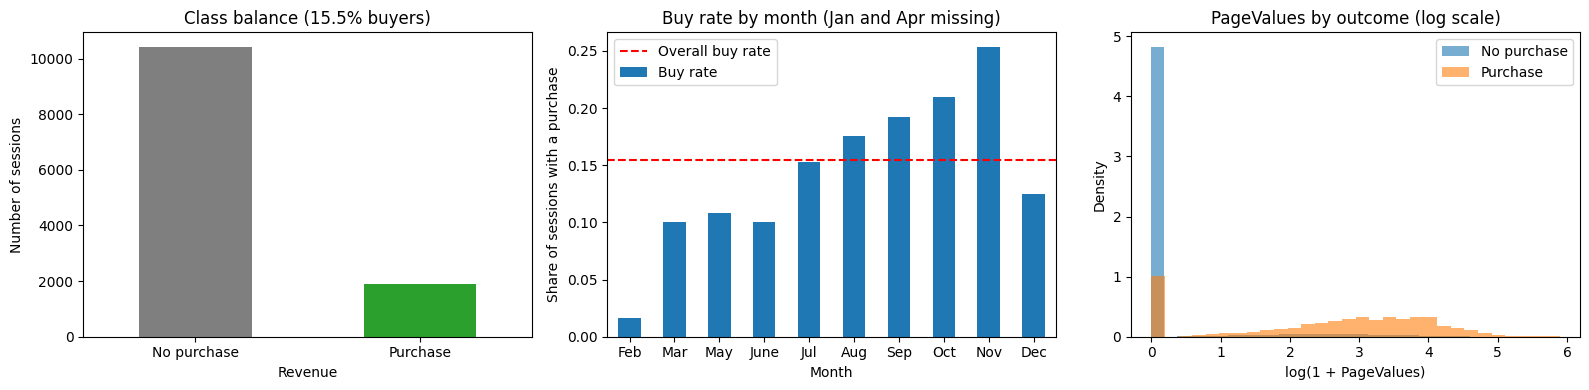

In [ ]:
# TODO: 1.3 Focused plots for the research question
import numpy as np
import matplotlib.pyplot as plt

month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
buy_rate_month = df.groupby("Month")["Revenue"].mean().reindex(month_order)
sessions_month = df["Month"].value_counts().reindex(month_order)
display(pd.DataFrame({"sessions": sessions_month, "buy_rate": buy_rate_month.round(3)}).T)
print("Buy rate by visitor type:", df.groupby("VisitorType")["Revenue"].mean().round(3).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Plot 1: class balance (astype(int) works whether Revenue is True/False or 1/0)
df["Revenue"].astype(int).map({0: "No purchase", 1: "Purchase"}).value_counts().plot(
    kind="bar", ax=axes[0], color=["tab:gray", "tab:green"])
axes[0].set_title("Class balance (15.5% buyers)")
axes[0].set_ylabel("Number of sessions")
axes[0].tick_params(axis="x", rotation=0)

# Plot 2: buy rate by month
buy_rate_month.plot(kind="bar", ax=axes[1], label="Buy rate")
axes[1].axhline(df["Revenue"].mean(), color="red", linestyle="--", label="Overall buy rate")
axes[1].set_title("Buy rate by month (Jan and Apr missing)")
axes[1].set_ylabel("Share of sessions with a purchase")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend()

# Plot 3: PageValues for buyers vs non-buyers (log scale, because PageValues is very skewed)
for label, grp in df.groupby(df["Revenue"].astype(int)):
    axes[2].hist(np.log1p(grp["PageValues"]), bins=30, alpha=0.6, density=True,
                 label="Purchase" if label == 1 else "No purchase")
axes[2].set_title("PageValues by outcome (log scale)")
axes[2].set_xlabel("log(1 + PageValues)")
axes[2].set_ylabel("Density")
axes[2].legend()

plt.tight_layout()
plt.show()

**Result (1.3):**

| Month | Feb | Mar | May | June | Jul | Aug | Sep | Oct | Nov | Dec |
|---|---|---|---|---|---|---|---|---|---|---|
| Sessions | 184 | 1,907 | 3,364 | 288 | 432 | 433 | 448 | 549 | 2,998 | 1,727 |
| Buy rate | 1.6% | 10.1% | 10.9% | 10.1% | 15.3% | 17.6% | 19.2% | 20.9% | **25.4%** | 12.5% |

- **Class balance:** only 1,908 of 12,330 sessions (15.5%) end in a purchase. A model that always says "no purchase" would already be 84.5% accurate,
  so accuracy is misleading. We use **PR-AUC** as the main metric and **class weighting** (Section 5).
- **Month matters, and not in a straight line:** the buy rate rises from February (1.6%) to a peak in **November (25.4%)**, then **drops in December (12.5%)**.
  Because the effect is not steadily increasing, Month is **one-hot encoded**, not treated as a number. **January and April are missing** from the data.
  May and November have the most sessions but very different buy rates (10.9% vs 25.4%).
- **Visitor type:** new visitors buy more often (24.9%) than returning visitors (13.9%).
- **PageValues separates the classes strongly:** most non-buyers have PageValues = 0 (tall blue bar at 0), while most buyers have PageValues > 0 (orange spread from 1 to 5 on the log scale).
  This suggests PageValues will be a key feature (confirmed in Section 7). Its values are very **skewed**, which is why it is log-transformed in preprocessing (Section 4).

## 2. Data Cleaning

### 2.1 Fix data types
- `Weekend` and `Revenue` are converted from True/False to 1/0 so models can use them.
- `OperatingSystems`, `Browser`, `Region` and `TrafficType` are anonymised ID codes with no documented meaning. A higher number is not "more", so they are converted to text and will be one-hot encoded later.
- Target: `Revenue` (1 = purchase, 0 = no purchase). About 15.5% of sessions are purchases, so the classes are imbalanced.



In [ ]:
# TODO: convert True/False columns to 1/0 so models can use them
df["Weekend"] = df["Weekend"].astype(int)
df["Revenue"] = df["Revenue"].astype(int)

# TODO: treat the 4 anonymised ID codes as categories, not numbers
code_cols = ["OperatingSystems", "Browser", "Region", "TrafficType"]
df[code_cols] = df[code_cols].astype(str)

# TODO: confirm the changes
print(df.dtypes)
print("\nBuyer share:", round(df["Revenue"].mean(), 3))

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems            object
Browser                     object
Region                      object
TrafficType                 object
VisitorType                 object
Weekend                      int64
Revenue                      int64
dtype: object

Buyer share: 0.155


### 2.2 Duplicate rows
125 rows are exact duplicates. Inspect them before deciding whether to keep or remove them.

In [ ]:
# TODO: look at what the duplicate rows have in common
dups = df.duplicated()
print("Duplicate rows:", dups.sum())
print("Buyers among duplicates:", df.loc[dups, "Revenue"].sum())

df.loc[dups, ["ProductRelated", "ProductRelated_Duration",
              "BounceRates", "ExitRates", "PageValues"]].describe()

Duplicate rows: 125
Buyers among duplicates: 0


,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues
count,125.000000,125.0,1.250000e+02,1.250000e+02,125.0
mean,1.056000,0.0,2.000000e-01,2.000000e-01,0.0
std,0.230847,0.0,4.737436e-16,4.737436e-16,0.0
min,1.000000,0.0,2.000000e-01,2.000000e-01,0.0
25%,1.000000,0.0,2.000000e-01,2.000000e-01,0.0
50%,1.000000,0.0,2.000000e-01,2.000000e-01,0.0
75%,1.000000,0.0,2.000000e-01,2.000000e-01,0.0
max,2.000000,0.0,2.000000e-01,2.000000e-01,0.0


**Decision: keep the 125 duplicates.**
They are all visitors who opened 1 page, stayed 0 seconds and left without buying. They look identical because these visits have very little information, not because they were copied. They are likely real, different people, so we keep them.

### 2.3 Value range checks
Check that values make sense: no negative durations, rates between 0 and 1, and valid categories.

In [ ]:
# TODO: durations can't be negative
print("Negative durations:", (df.filter(like="Duration") < 0).sum().sum())

# TODO: bounce and exit rates must be between 0 and 1
rates = df[["BounceRates", "ExitRates"]]
print("Rates outside 0-1:", ((rates < 0) | (rates > 1)).sum().sum())

# TODO: check the allowed values of the other columns
print("SpecialDay values:", sorted(df["SpecialDay"].unique().tolist()))
print("Months present:", df["Month"].unique().tolist())
print("VisitorType:", df["VisitorType"].value_counts().to_dict())

Negative durations: 0
Rates outside 0-1: 0
SpecialDay values: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
Months present: ['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
VisitorType: {'Returning_Visitor': 10551, 'New_Visitor': 1694, 'Other': 85}


## 3. Train / Validation / Test Split

The data is split into three sets **before any encoding or scaling**:

| Set | Share | Rows (approx.) | Used for |
|---|---|---|---|
| **Train** | 60% | ~7,400 | Fitting the models and tuning hyperparameters (with cross-validation) |
| **Validation** | 20% | ~2,470 | Comparing models, choosing the classification threshold, and running the feature ablation |
| **Test** | 20% | ~2,470 | Used **only once** at the end to report the final result |

**Why split before scaling?**
The test set must stay completely unseen, like a final exam. Scaling learns averages and spreads from the data. If it were done before splitting, information from the test set would leak into training and make the results look better than they really are.

**Why split before encoding too?**
One-hot encoding before the split would be a much smaller issue, but doing it after the split is cleaner for two reasons:
1. **Rare categories:** some codes appear in only a few sessions (e.g., `TrafficType 12` appears once). The encoder groups codes that are rare *in the training set* into one "infrequent" column. This decision should come from training data only.
2. **One pipeline:** encoding and scaling are done together in one scikit-learn Pipeline (Section 4). It is fitted on the training set and applied to validation and test automatically. This also makes cross-validation and the later feature ablation simpler and leakage-free.

**Why stratified?**
Only about 15.5% of sessions are purchases. A stratified split keeps this same share in all three sets, so no set ends up with too few buyers by chance.

**How the split is done:**
1. Take 20% of the data out as the **test** set.
2. Split the remaining 80% into **train** (75% of it = 60% overall) and **validation** (25% of it = 20% overall).

`random_state = 42` is fixed, so the split is the same every time the notebook runs.

In [ ]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# TODO: separate features (X) from the target (y)
X = df.drop(columns="Revenue")
y = df["Revenue"]

# TODO: first take 20% out as the test set
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

# TODO: split the remaining 80% into train (60%) and validation (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE)

# TODO: check sizes and buyer share in each set
for name, part in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:10s}: {len(part):5d} rows, buyer share = {part.mean():.3f}")

Train     :  7398 rows, buyer share = 0.155
Validation:  2466 rows, buyer share = 0.155
Test      :  2466 rows, buyer share = 0.155


### 3.1 Save the split (optional)

In [ ]:
# TODO: (optional) save each split to CSV
X_train.assign(Revenue=y_train).to_csv("train.csv", index=False)
X_val.assign(Revenue=y_val).to_csv("val.csv", index=False)
X_test.assign(Revenue=y_test).to_csv("test.csv", index=False)
print("Saved train.csv, val.csv, test.csv")

Saved train.csv, val.csv, test.csv


## 4. Preprocessing Pipeline

### 4.1 Feature groups
Features are grouped in two ways:
1. **By meaning**: used later for the ablation study (removing one group at a time).
2. **By how they are processed**:
   - **Skewed** (counts, durations, PageValues): most values are small but a few are very large, so they are log-transformed and then scaled.
   - **Numeric** (BounceRates, ExitRates, SpecialDay): already between 0 and 1, so they are only scaled.
   - **Categorical** (Month, VisitorType and the 4 code columns): one-hot encoded.
   - **Binary** (Weekend): already 0/1, so it is left as it is.

In [ ]:
# TODO: groups by MEANING (used later for ablation)
page_behaviour = ["Administrative", "Administrative_Duration",
                  "Informational", "Informational_Duration",
                  "ProductRelated", "ProductRelated_Duration"]
engagement     = ["BounceRates", "ExitRates", "PageValues"]
time_context   = ["Month", "SpecialDay", "Weekend"]
visitor_tech   = ["VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]

ALL_FEATURES = page_behaviour + engagement + time_context + visitor_tech

# TODO: groups by HOW each column is processed
SKEWED      = page_behaviour + ["PageValues"]
NUMERIC     = ["BounceRates", "ExitRates", "SpecialDay"]
CATEGORICAL = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
BINARY      = ["Weekend"]

# TODO: check every feature is in exactly one processing group
assert sorted(SKEWED + NUMERIC + CATEGORICAL + BINARY) == sorted(ALL_FEATURES)
print("Total features:", len(ALL_FEATURES))
print(f"Skewed: {len(SKEWED)}, Numeric: {len(NUMERIC)}, Categorical: {len(CATEGORICAL)}, Binary: {len(BINARY)}")

Total features: 17
Skewed: 7, Numeric: 3, Categorical: 6, Binary: 1


#### 4.1b Why log-transform? Checking skewness
Skewness measures how lopsided a feature's distribution is: 0 = symmetric; values above about 1 = a long right tail (a few very large values).
We compare the skewness of the "skewed" group before and after `log(1 + x)`, on the **training set only**.

In [ ]:
# TODO: 4.1b skewness before and after log(1 + x), training set only
import numpy as np

skew_df = pd.DataFrame({
    "skew_before": X_train[SKEWED].skew(),
    "skew_after_log1p": np.log1p(X_train[SKEWED]).skew(),
}).round(2)
display(skew_df)
print("Numeric (not log-transformed) for comparison:")
display(X_train[NUMERIC].skew().round(2).to_frame("skew"))

,skew_before,skew_after_log1p
Administrative,2.04,0.60
Administrative_Duration,5.97,0.29
Informational,4.33,2.05
Informational_Duration,7.72,1.91
ProductRelated,4.31,-0.05
ProductRelated_Duration,8.86,-1.40
PageValues,6.49,1.83


Numeric (not log-transformed) for comparison:


,skew
BounceRates,2.83
ExitRates,2.07
SpecialDay,3.18


**Result (4.1b):**

| Feature | Skew before | Skew after log(1 + x) |
|---|---|---|
| Administrative | 2.04 | 0.60 |
| Administrative_Duration | 5.97 | 0.29 |
| Informational | 4.33 | 2.05 |
| Informational_Duration | 7.72 | 1.91 |
| ProductRelated | 4.31 | −0.05 |
| ProductRelated_Duration | 8.86 | −1.40 |
| PageValues | 6.49 | 1.83 |

- All 7 count, duration and PageValues features are **strongly right-skewed** (skew 2.0–8.9): most sessions have small values, a few have very large ones.
- `log(1 + x)` **reduces the skew a lot** (e.g. ProductRelated 4.31 → −0.05, PageValues 6.49 → 1.83), so a few extreme sessions no longer dominate the scaling.
  Some features stay somewhat skewed (Informational, PageValues) because most of their values are exactly 0, which no transformation can spread out.
  ProductRelated_Duration becomes slightly left-skewed (−1.40), for the same reason: a group of zero-duration sessions.
- **BounceRates, ExitRates and SpecialDay are also skewed (2.1–3.2) but were not log-transformed.** They are small rates between 0 and 1 (Bounce/Exit at most 0.2),
  where log(1 + x) ≈ x, so the transform would barely change them. SpecialDay only takes 6 values (0, 0.2, …, 1). They are only standardised.
- The log transform mainly helps **Logistic Regression**, which is sensitive to extreme values. Random Forest splits on the order of values,
  so a log transform does not change its results.

### 4.2 Build the preprocessor
A `ColumnTransformer` applies a different preparation step to each feature group:
- **Skewed:** `log(1 + x)` to shrink very large values, then standardise (mean 0, std 1)
- **Numeric:** standardise only
- **Categorical:** one-hot encode; codes seen fewer than 10 times in training are merged into one "infrequent" column, and unseen codes are ignored
- **Binary:** left unchanged

It is wrapped in a function so the ablation study can rebuild it for any subset of features.

In [ ]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

def make_preprocessor(features=ALL_FEATURES):
    # TODO: keep only the columns that are in this feature set
    skewed      = [c for c in SKEWED if c in features]
    numeric     = [c for c in NUMERIC if c in features]
    categorical = [c for c in CATEGORICAL if c in features]
    binary      = [c for c in BINARY if c in features]

    steps = []
    # TODO: skewed -> log then scale
    if skewed:
        steps.append(("skewed", Pipeline([
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", StandardScaler()),
        ]), skewed))
    # TODO: numeric -> scale only
    if numeric:
        steps.append(("numeric", StandardScaler(), numeric))
    # TODO: categorical -> one-hot, rare codes grouped
    if categorical:
        steps.append(("categorical", OneHotEncoder(
            handle_unknown="infrequent_if_exist", min_frequency=10,
            sparse_output=False), categorical))
    # TODO: binary -> unchanged
    if binary:
        steps.append(("binary", "passthrough", binary))

    return ColumnTransformer(steps, verbose_feature_names_out=False)

preprocessor = make_preprocessor()
preprocessor

ColumnTransformer(transformers=[('skewed',
                                 Pipeline(steps=[('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scale', StandardScaler())]),
                                 ['Administrative', 'Administrative_Duration',
                                  'Informational', 'Informational_Duration',
                                  'ProductRelated', 'ProductRelated_Duration',
                                  'PageValues']),
                                ('numeric', StandardScaler(),
                                 ['BounceRates', 'ExitRates', 'SpecialDay']),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='infrequent_if_exist',
                                               min_frequency=10,
                                               sparse_output=False),
                                 ['Month', 'VisitorType', 'OperatingSystems',
                                  'Browser', 'Region', 'TrafficType']),
                                ('binary', 'passthrough', ['Weekend'])],
                  verbose_feature_names_out=False)

### 4.3 Check the preprocessor
Test it once: fit on the **training set only**, then apply the same transformation to validation and test. This is just a check. For modelling, the preprocessor goes inside a Pipeline with each model (Section 5).

In [ ]:
# TODO: fit on TRAIN only, then apply to val and test
Xt_train = preprocessor.fit_transform(X_train)
Xt_val   = preprocessor.transform(X_val)
Xt_test  = preprocessor.transform(X_test)

# TODO: check shapes and missing values
print("Shapes:", Xt_train.shape, Xt_val.shape, Xt_test.shape)
print("Any NaN:", np.isnan(Xt_train).any() or np.isnan(Xt_val).any() or np.isnan(Xt_test).any())

# TODO: look at the new column names
feature_names = preprocessor.get_feature_names_out()
print(f"\n{len(feature_names)} columns after preprocessing:")
print(list(feature_names))

# TODO: scaled columns should have mean ~0 and std ~1 on train
pd.DataFrame(Xt_train, columns=feature_names).describe().T[["mean", "std", "min", "max"]].round(2).head(10)

Shapes: (7398, 66) (2466, 66) (2466, 66)
Any NaN: False

66 columns after preprocessing:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'PageValues', 'BounceRates', 'ExitRates', 'SpecialDay', 'Month_Aug', 'Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_June', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_New_Visitor', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'OperatingSystems_1', 'OperatingSystems_2', 'OperatingSystems_3', 'OperatingSystems_4', 'OperatingSystems_6', 'OperatingSystems_8', 'OperatingSystems_infrequent_sklearn', 'Browser_1', 'Browser_10', 'Browser_13', 'Browser_2', 'Browser_3', 'Browser_4', 'Browser_5', 'Browser_6', 'Browser_7', 'Browser_8', 'Browser_infrequent_sklearn', 'Region_1', 'Region_2', 'Region_3', 'Region_4', 'Region_5', 'Region_6', 'Region_7', 'Region_8', 'Region_9', 'TrafficType_1', 'TrafficType_10', 'TrafficType_11', 'TrafficType_13

,mean,std,min,max
Administrative,0.0,1.0,-0.91,2.83
Administrative_Duration,0.0,1.0,-0.96,2.48
Informational,0.0,1.0,-0.48,5.98
Informational_Duration,0.0,1.0,-0.47,3.84
ProductRelated,0.0,1.0,-2.53,3.27
ProductRelated_Duration,0.0,1.0,-2.83,2.46
PageValues,-0.0,1.0,-0.49,4.17
BounceRates,0.0,1.0,-0.46,3.52
ExitRates,0.0,1.0,-0.89,3.11
SpecialDay,-0.0,1.0,-0.32,4.59


### 4.4 Save the processed data (for inspection only)
The encoded and scaled sets are saved so they can be inspected outside the notebook. Models do **not** use these files: the Pipeline re-does preprocessing inside cross-validation from the raw training data.

In [ ]:
# TODO: turn the processed arrays back into tables with column names
train_processed = pd.DataFrame(Xt_train, columns=feature_names).assign(Revenue=y_train.values)
val_processed   = pd.DataFrame(Xt_val,   columns=feature_names).assign(Revenue=y_val.values)
test_processed  = pd.DataFrame(Xt_test,  columns=feature_names).assign(Revenue=y_test.values)

# TODO: save to CSV
train_processed.to_csv("train_processed.csv", index=False)
val_processed.to_csv("val_processed.csv", index=False)
test_processed.to_csv("test_processed.csv", index=False)

print("Saved:", train_processed.shape, val_processed.shape, test_processed.shape)
train_processed.head()

Saved: (7398, 67) (2466, 67) (2466, 67)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,PageValues,BounceRates,ExitRates,SpecialDay,...,TrafficType_3,TrafficType_4,TrafficType_5,TrafficType_6,TrafficType_7,TrafficType_8,TrafficType_9,TrafficType_infrequent_sklearn,Weekend,Revenue
0,0.699310,0.985613,-0.476958,-0.465960,-0.944900,-0.860886,-0.488245,-0.464691,-0.386177,-0.317659,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,-0.909616,-0.960367,-0.476958,-0.465960,-0.135140,-0.008972,-0.488245,-0.085274,0.033320,-0.317659,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
2,-0.105153,-0.960367,-0.476958,-0.465960,0.073766,-0.238465,-0.488245,0.282287,0.363410,-0.317659,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
3,1.974353,1.303552,1.727232,2.111945,1.013085,0.978943,-0.488245,-0.464691,-0.456760,-0.317659,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,-0.909616,-0.960367,-0.476958,-0.465960,0.534455,0.137305,-0.488245,-0.464691,-0.756941,-0.317659,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0


**Result:** After preprocessing, the 17 original features become 66 columns (mainly from one-hot encoding). There are no missing values, and the scaled columns have mean 0 and standard deviation 1 on the training set. Validation and test were transformed using what was learned from training only.

## 5. Model Selection

### 5.0 Choice of evaluation metric

**Main metric: PR-AUC** (Precision–Recall Area Under Curve).
In scikit-learn it is called `average_precision`.

**What it measures:** for every possible threshold, the model gives a precision (of predicted buyers, how many really buy)
and a recall (of real buyers, how many we catch). PR-AUC summarises this whole precision–recall curve in one number.
- Perfect model = 1.0
- Random guessing = the share of buyers ≈ **0.155**

**Why PR-AUC for choosing hyperparameters and models:**
| Metric | Problem with our data |
|---|---|
| Accuracy | Misleading with imbalance: predicting "no buyer" for everyone already gets ≈ 84.5% |
| Precision / Recall / F1 | Depend on the **threshold**, which we choose separately in Section 6. Using them now would mix two decisions. |
| ROC-AUC | Threshold-free, but **too optimistic** with imbalance: the many easy non-buyers make every model look good |
| **PR-AUC** ✅ | **Threshold-free** and **focused on the buyer class**, which is what our research question is about (finding buyers while controlling false positives) |

**Where we use it:**
- Hyperparameter tuning of **both** models: `GridSearchCV(scoring="average_precision")` for Logistic Regression (C) and Random Forest (depth, leaf size, max_features)
- Comparing LR vs RF, the number of trees, PCA, permutation importance and ablation

**Other metrics are still reported:** ROC-AUC, precision, recall, F1, accuracy and the confusion matrix are shown on validation (5.4–5.5) and on the test set (Section 8),
but all **decisions** are made with one main metric, so we don't pick whichever metric looks best.

**Order of decisions:**
1. Section 5: choose the model and hyperparameters → **PR-AUC** (threshold-free)
2. Section 6: choose the threshold → **F1, precision, recall**
3. Section 8: report all metrics on the test set once

### 5.1 Baseline
A **majority-class baseline** predicts "no purchase" for every session. Any useful model must beat it.

An `evaluate()` function is defined once and reused for every model. It reports accuracy, precision, recall, F1, PR-AUC and the confusion matrix. **PR-AUC is the main metric**, because it focuses on the rare purchase class and does not depend on a threshold.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, confusion_matrix)

def evaluate(name, model, X, y, threshold=0.5):
    # TODO: probability of "purchase" for each session
    proba = model.predict_proba(X)[:, 1]
    # TODO: turn probabilities into 0/1 using the threshold
    pred = (proba >= threshold).astype(int)
    return {
        "model": name,
        "accuracy":  accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall":    recall_score(y, pred),
        "f1":        f1_score(y, pred),
        "pr_auc":    average_precision_score(y, proba),
    }

# TODO: baseline = always predict the most common class (no purchase)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

results = [evaluate("Baseline", baseline, X_val, y_val)]
display(pd.DataFrame(results).round(3))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_val, baseline.predict(X_val)))

,model,accuracy,precision,recall,f1,pr_auc
0,Baseline,0.845,0.0,0.0,0.0,0.155


Confusion matrix (rows = actual, columns = predicted):
[[2085    0]
 [ 381    0]]


### 5.2 Tune Logistic Regression

**What is Logistic Regression?**
Logistic Regression gives each feature a weight that pushes the prediction towards "purchase" or "no purchase". It combines these into a probability between 0 and 1. It is a simple, interpretable model: the sign of each weight shows the direction of a feature's effect.

**Setup:**
- Preprocessing and model are combined in a Pipeline, so preprocessing is re-fitted inside each CV fold (no leakage).
- **5-fold stratified cross-validation** on the training set only, scored by **PR-AUC**.

**Parameters vs hyperparameters:**
- **Parameters** are learned from the data: one weight per feature plus an intercept.
- **Hyperparameters** are settings chosen before training. There is **no learning rate**, because scikit-learn's default `lbfgs` solver sets its own step size.

**Hyperparameter tuned:** `C`, the regularisation strength. Smaller C = simpler, more restricted model; larger C = more flexible model.

**Search space:** 13 values of C from **0.0001 to 100**:
`0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100`

The values are spaced on a **logarithmic scale**, with two values for every ×10 step (each value is about 3× the previous one). A log scale is used because C's effect depends on its order of magnitude: moving from 1 to 10 matters, while moving from 1 to 2 barely changes anything. This covers six orders of magnitude, from very restricted to very flexible, with 13 × 5 = 65 model fits.

**Hyperparameters fixed (not tuned):**

| Hyperparameter | Value | Reason |
|---|---|---|
| `penalty` | "l2" (default) | Shrinks all weights smoothly; standard and stable |
| `solver` | "lbfgs" (default) | Works well for this data size and sets its own step size |
| `class_weight` | "balanced" | Handles the class imbalance (see below) |
| `max_iter` | 2000 | Enough steps for training to finish; does not affect performance |

**Handling class imbalance:**
1. `class_weight="balanced"`: mistakes on buyers count about 5.5× more in training, matching how much rarer they are.
2. **Stratified folds:** every CV fold keeps the 15.5% buyer share.
3. **PR-AUC scoring:** C is chosen by how well buyers are found, not by accuracy.
4. **Threshold tuning** (Section 6) adjusts the decision cut-off afterwards.

Oversampling methods such as SMOTE were not used, because class weighting achieves a similar effect without creating synthetic data.


**Why no learning rate?** scikit-learn trains Logistic Regression with the **lbfgs** solver, which chooses its own step sizes automatically.
So there is no learning rate to tune; the main hyperparameter is **C** (regularisation strength).

Best C: 0.01
Best CV PR-AUC: 0.672


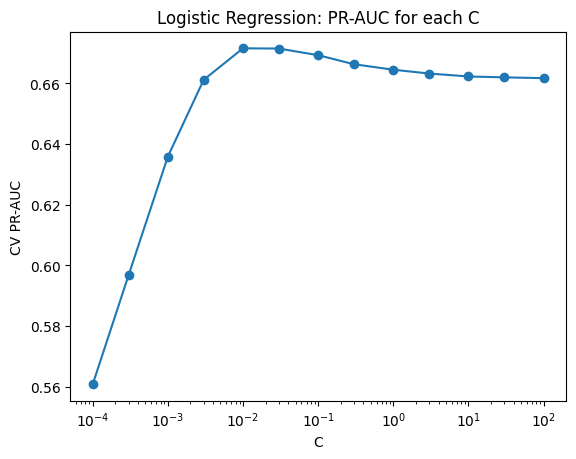

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import matplotlib.pyplot as plt

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# TODO: preprocessor + model in one pipeline
lr_pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000)),
])

# TODO: C values to try (log scale, each about 3x the previous)
C_values = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]

# TODO: try every C with 5-fold CV on the training set
lr_grid = GridSearchCV(lr_pipe, {"model__C": C_values},
                       scoring="average_precision", cv=cv)
lr_grid.fit(X_train, y_train)

print("Best C:", lr_grid.best_params_["model__C"])
print("Best CV PR-AUC:", round(lr_grid.best_score_, 3))

# TODO: plot the score for each C
scores = lr_grid.cv_results_["mean_test_score"]
plt.plot(C_values, scores, marker="o")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("CV PR-AUC")
plt.title("Logistic Regression: PR-AUC for each C")
plt.show()

**Result: C = 0.01 is chosen** (CV PR-AUC = **0.672**, compared with 0.155 for the baseline).

What the graph shows:
- **Very small C (0.0001–0.001):** the model is too restricted to learn the patterns, so PR-AUC is clearly lower (down to 0.56). This is **underfitting**.
- **C = 0.01 to 0.03:** the peak, with the best balance between simplicity and flexibility.
- **Larger C (0.1–100):** PR-AUC drops only slightly and then levels off at about 0.66. Extra flexibility does not help, and the model is not very sensitive to C in this range.

The best value lies **inside** the search range, not at its edge, so the range was wide enough. C = 0.01 and C = 0.03 score almost the same; the smaller value is preferred because it gives the simpler model.

**Note on hyperparameters:** Logistic Regression learns one weight per feature (its *parameters*). Its main *hyperparameter* is C. There is no learning rate to tune, because scikit-learn's default `lbfgs` solver sets its own step size. Other settings were fixed: `penalty="l2"` (default), `class_weight="balanced"` and `max_iter=2000`.

### 5.3 Tune Random Forest

**What is a Random Forest?**
A Random Forest is a group of many decision trees. Each tree is trained on a random sample of the training sessions and asks a series of yes/no questions (for example, *"Is PageValues > 0.5?"*). For each new session, every tree votes, and the forest gives the share of "purchase" votes as its probability.

**Setup (same as Logistic Regression):**
- Preprocessing and model are combined in a Pipeline, so preprocessing is re-fitted inside each CV fold (no leakage).
- **5-fold stratified cross-validation** on the training set only, scored by **PR-AUC**.
- `class_weight="balanced"` handles the class imbalance (mistakes on buyers count more).

**Parameters vs hyperparameters:**
- **Parameters** are learned by the model from the data. For Random Forest, these are the tree splits: which feature each tree splits on, and at what value.
- **Hyperparameters** are settings chosen before training. There is **no learning rate**, because trees are built by splitting the data, not by gradient descent.

**Hyperparameters tuned (3 × 2 × 2 = 12 combinations, 60 model fits):**

| Hyperparameter | Values tried | What it controls |
|---|---|---|
| `max_depth` | None, 10, 20 | How deep each tree can grow (None = no limit). Deeper trees capture more detail but can memorise the training data (overfit). |
| `min_samples_leaf` | 1, 5 | Minimum number of sessions in each final leaf. Larger values give smoother rules and less overfitting. |
| `max_features` | "sqrt", 0.5 | How many features each split may consider: √66 ≈ 8, or 50% = 33. Fewer features make the trees more different from each other, which makes the combined vote stronger. |

These three were chosen because they have the biggest effect on overfitting in Random Forest.

**Hyperparameters fixed (not tuned):**

| Hyperparameter | Value | Reason |
|---|---|---|
| `n_estimators` | 300 | Number of trees. More trees only make results more stable, not worse, so 300 is enough. |
| `class_weight` | "balanced" | Handles the class imbalance. |
| `criterion` | "gini" (default) | How the quality of a split is measured. The default works well. |
| `bootstrap` | True (default) | Each tree trains on a random sample of rows, which is what makes the forest "random". |
| `random_state` | 42 | Makes results reproducible. It does not affect performance. |





**Why no learning rate?** A Random Forest is not trained with gradient steps. Each tree is built by splitting the data,
so there is no learning rate. A learning rate appears in gradient-based models (neural networks, gradient boosting), which we do not use.



**How the Random Forest is trained (bagging):**
Each of the 300 trees is trained on a **bootstrap sample** of the training set (rows drawn at random *with replacement*, about 63% of the rows),
and at each split it considers a random 50% of the features (`max_features = 0.5`). The ~37% of rows a tree does not see are called **out-of-bag (OOB)**.
Averaging many different trees makes the forest stable and reduces overfitting.

**Why we did not use the OOB score:** Random Forest can estimate performance (or tune hyperparameters) from the OOB rows,
which is about 5× faster than cross-validation. We used **5-fold cross-validation and a separate validation set** instead, because:
- we compare two models (LR and RF), and only RF has OOB, so CV lets us tune both **the same way**;
- the default OOB score is **accuracy**, which is misleading with 15% buyers (we use PR-AUC);
- the dataset is large enough for a clean train / validation / test split.

OOB is most useful for **small datasets**, **RF-only projects**, when CV is **too slow**, or after retraining on all data.
It never replaces the held-out **test set**.



| Use OOB when… | Use CV + validation (our choice) when… |
|---|---|
| Small dataset | Large enough for train / val / test |
| Only Random Forests | Comparing different models (LR vs RF) |
| CV too slow | Time is not a problem |
| Retrained on all data | Need PR-AUC, threshold tuning, feature analysis |

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# TODO: preprocessor + random forest in one pipeline
rf_pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                     random_state=RANDOM_STATE, n_jobs=-1)),
])

# TODO: hyperparameter values to try
rf_params = {
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 5],
    "model__max_features": ["sqrt", 0.5],
}

# TODO: try every combination with 5-fold CV on the training set
rf_grid = GridSearchCV(rf_pipe, rf_params, scoring="average_precision", cv=cv)
rf_grid.fit(X_train, y_train)

print("Best settings:", rf_grid.best_params_)
print("Best CV PR-AUC:", round(rf_grid.best_score_, 3))

# TODO: show all 12 results, best first
results_rf = pd.DataFrame(rf_grid.cv_results_)
results_rf = results_rf[["params", "mean_test_score"]].sort_values("mean_test_score", ascending=False)
results_rf.round(3)

Best settings: {'model__max_depth': 10, 'model__max_features': 0.5, 'model__min_samples_leaf': 5}
Best CV PR-AUC: 0.748


,params,mean_test_score
7,"{'model__max_depth': 10, 'model__max_features'...",0.748
3,"{'model__max_depth': None, 'model__max_feature...",0.748
11,"{'model__max_depth': 20, 'model__max_features'...",0.747
0,"{'model__max_depth': None, 'model__max_feature...",0.744
8,"{'model__max_depth': 20, 'model__max_features'...",0.736
10,"{'model__max_depth': 20, 'model__max_features'...",0.736
6,"{'model__max_depth': 10, 'model__max_features'...",0.734
2,"{'model__max_depth': None, 'model__max_feature...",0.733
9,"{'model__max_depth': 20, 'model__max_features'...",0.730
1,"{'model__max_depth': None, 'model__max_feature...",0.729


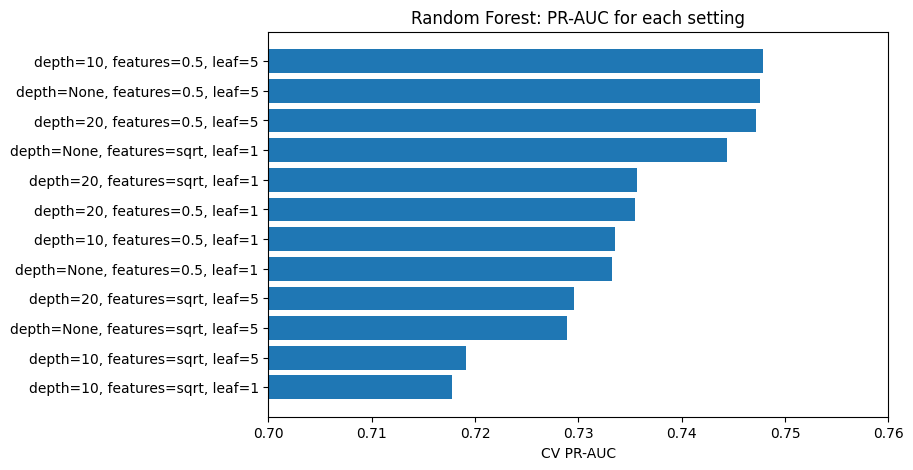

In [ ]:
# TODO: show each combination as readable text
res = pd.DataFrame(rf_grid.cv_results_)
res["setting"] = ("depth=" + res["param_model__max_depth"].astype(str)
                  + ", features=" + res["param_model__max_features"].astype(str)
                  + ", leaf=" + res["param_model__min_samples_leaf"].astype(str))
res = res.sort_values("mean_test_score")

# TODO: bar chart of CV PR-AUC for all 12 combinations
plt.figure(figsize=(8, 5))
plt.barh(res["setting"], res["mean_test_score"])
plt.xlim(0.70, 0.76)
plt.xlabel("CV PR-AUC")
plt.title("Random Forest: PR-AUC for each setting")
plt.show()

**Result:** Best settings: `max_depth=10`, `max_features=0.5`, `min_samples_leaf=5` (CV PR-AUC = **0.748**, compared with 0.672 for Logistic Regression and 0.155 for the baseline).

**What the tuning shows (see the bar chart above):**
- The top three combinations all use `max_features=0.5` and `min_samples_leaf=5` (0.747–0.748); this combination had the biggest effect.
- `max_depth` made almost no difference (10, 20 and None all scored about 0.748). Depth 10 was selected; it gives the simplest trees with the same score.
- `max_features=0.5` works best **together with** `min_samples_leaf=5`, while every `sqrt` + `leaf=5` setting scored lower (0.719–0.730).
  With `leaf=1` the picture is mixed (e.g. `depth=None, sqrt, leaf=1` reaches 0.744), so the settings interact: the winning combination is **0.5 features + leaf 5**.
- All 12 settings scored between 0.718 and 0.748, so Random Forest is fairly robust to these choices.

**Why 300 trees?**
The number of trees (`n_estimators`) was fixed at 300 rather than tuned. In a Random Forest, the final prediction is the average vote of all trees, so adding trees:
- makes the prediction **more stable**, because odd trees have less influence;
- **does not cause overfitting**: the score stops improving but does not get worse;
- makes training **slower**.

**Where this comes from:**
- **Breiman (2001)**, who introduced Random Forests, showed that adding more trees does not cause overfitting; the error settles to a stable value as the number of trees grows.
- **Oshiro, Perez & Baranauskas (2012)**, *"How Many Trees in a Random Forest?"*, tested many datasets and found that beyond about 128 trees the gain in performance was very small.
- **Probst & Boulesteix (2018)**, *"To tune or not to tune the number of trees in random forest"* (Journal of Machine Learning Research), concluded that the number of trees should not be tuned like other hyperparameters: it should simply be set "large enough", since more trees do not hurt performance.
- **scikit-learn** uses 100 trees as its default.

Based on this, performance typically levels off after a few hundred trees, so there is no single "best" value to search for, only "enough". 300 is a common rule-of-thumb choice: above scikit-learn's default of 100 for extra stability, while keeping training time reasonable on Colab (about 3–6 minutes for the full grid search). Section 5.3b checks this directly.

#### 5.3b Check: is 300 trees enough?

The number of trees is **not tuned** like the other hyperparameters. More trees never cause overfitting in a Random Forest;
the average over more trees simply becomes **more stable**. We only need *enough* trees for the score to stop changing.

Check: retrain the best RF (same settings) with 10 … 1000 trees and score it on validation.

   10 trees: PR-AUC = 0.718
   25 trees: PR-AUC = 0.731
   50 trees: PR-AUC = 0.735
  100 trees: PR-AUC = 0.737
  200 trees: PR-AUC = 0.735
  300 trees: PR-AUC = 0.737
  500 trees: PR-AUC = 0.736
 1000 trees: PR-AUC = 0.737


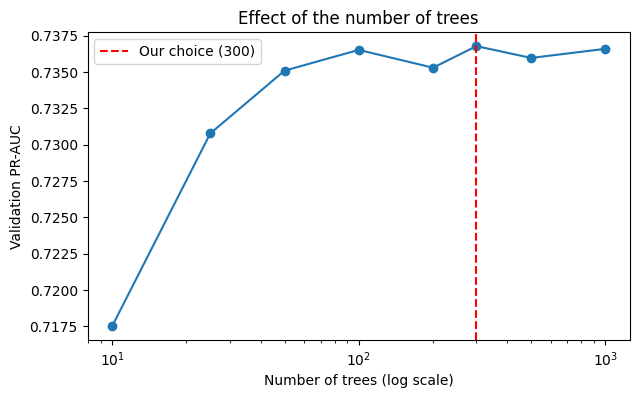

In [ ]:
# TODO: 5.3b Check number of trees (same best settings, only n_estimators changes)
from sklearn.base import clone
best_rf = rf_grid.best_estimator_

tree_counts = [10, 25, 50, 100, 200, 300, 500, 1000]
tree_scores = []
for n in tree_counts:
    rf_n = clone(best_rf).set_params(model__n_estimators=n)
    rf_n.fit(X_train, y_train)
    tree_scores.append(average_precision_score(y_val, rf_n.predict_proba(X_val)[:, 1]))
    print(f"{n:5d} trees: PR-AUC = {tree_scores[-1]:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(tree_counts, tree_scores, marker="o")
plt.axvline(300, color="red", linestyle="--", label="Our choice (300)")
plt.xscale("log")
plt.xlabel("Number of trees (log scale)")
plt.ylabel("Validation PR-AUC")
plt.title("Effect of the number of trees")
plt.legend()
plt.show()

**Result (5.3b):**

| Trees | 10 | 25 | 50 | 100 | 200 | 300 | 500 | 1000 |
|---|---|---|---|---|---|---|---|---|
| PR-AUC | 0.718 | 0.731 | 0.735 | 0.737 | 0.735 | 0.737 | 0.736 | 0.737 |

- PR-AUC rises quickly up to about **50–100 trees**, then stays **flat** (0.735–0.737). The differences after that are random noise (note the zoomed y-axis).
- **300 trees** is safely on the plateau. 1000 trees gives the same score and takes about 3× longer to train.
- As expected, more trees do **not** cause overfitting: the score stabilises instead of dropping.

**Why PR-AUC:** we use the same metric as in the grid search. It does not depend on a threshold (chosen later in Section 6),
and it focuses on the buyer class, unlike accuracy (misleading at 15% buyers) or ROC-AUC (optimistic with imbalance).

**Conclusion:** 300 trees is a justified choice.

### 5.4 Compare models on the validation set
The best Logistic Regression and Random Forest from cross-validation are now evaluated on the **validation set**, which neither model has seen. They are compared with the baseline.

- **Main metric:** PR-AUC (does not depend on the threshold).
- Precision, recall and F1 use the default threshold of **0.5**; the threshold is tuned separately in Section 6.
- **Selection rule:** choose the model with the higher validation PR-AUC; if the two are within about 0.02, prefer Logistic Regression because it is simpler.

In [ ]:
# TODO: get the best model from each grid search
best_lr = lr_grid.best_estimator_
best_rf = rf_grid.best_estimator_

# TODO: evaluate all three on the validation set
results = [
    evaluate("Baseline", baseline, X_val, y_val),
    evaluate("Logistic Regression", best_lr, X_val, y_val),
    evaluate("Random Forest", best_rf, X_val, y_val),
]
display(pd.DataFrame(results).round(3))

# TODO: confusion matrices (rows = actual, columns = predicted)
print("Logistic Regression:")
print(confusion_matrix(y_val, best_lr.predict(X_val)))
print("\nRandom Forest:")
print(confusion_matrix(y_val, best_rf.predict(X_val)))

,model,accuracy,precision,recall,f1,pr_auc
0,Baseline,0.845,0.000,0.000,0.000,0.155
1,Logistic Regression,0.882,0.582,0.848,0.690,0.687
2,Random Forest,0.883,0.587,0.816,0.683,0.737


Logistic Regression:
[[1853  232]
 [  58  323]]

Random Forest:
[[1866  219]
 [  70  311]]


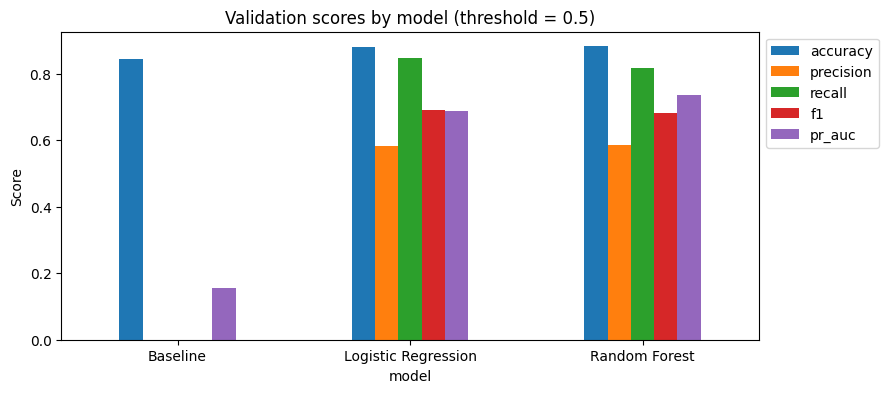

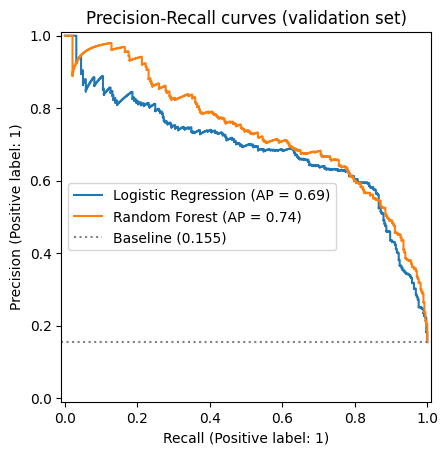

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay

# TODO: Graph 1 - bar chart of all metrics for the 3 models
pd.DataFrame(results).set_index("model").plot(kind="bar", figsize=(9, 4))
plt.ylabel("Score")
plt.title("Validation scores by model (threshold = 0.5)")
plt.xticks(rotation=0)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

# TODO: Graph 2 - precision-recall curves
ax = plt.gca()
PrecisionRecallDisplay.from_estimator(best_lr, X_val, y_val, name="Logistic Regression", ax=ax)
PrecisionRecallDisplay.from_estimator(best_rf, X_val, y_val, name="Random Forest", ax=ax)
plt.axhline(y_val.mean(), color="gray", linestyle=":", label="Baseline (0.155)")
plt.title("Precision-Recall curves (validation set)")
plt.legend()
plt.show()

**Result:**

| Model | Accuracy | Precision | Recall | F1 | PR-AUC |
|---|---|---|---|---|---|
| Baseline | 0.845 | 0.000 | 0.000 | 0.000 | 0.155 |
| Logistic Regression | 0.882 | 0.582 | 0.848 | 0.690 | 0.687 |
| Random Forest | 0.883 | 0.587 | 0.816 | 0.683 | **0.737** |

- Both models clearly beat the baseline, which reaches 84.5% accuracy but finds no buyers.
- **Random Forest has the highest PR-AUC (0.737 vs 0.687).** The 0.05 gap is larger than the 0.02 margin set in advance, so **Random Forest is selected**. Its precision-recall curve lies above Logistic Regression's for most thresholds.
- At the default threshold of 0.5, Logistic Regression catches slightly more buyers (323 vs 311) but makes more false alarms (232 vs 219). These threshold-based metrics depend on the cut-off; PR-AUC compares models across all thresholds, which is why it is the main metric.
- Validation PR-AUC is close to the CV scores (RF 0.748, LR 0.672), so neither model appears to overfit.
- Logistic Regression is kept as an interpretable reference for the feature-importance analysis.

### 5.5 Fair comparison: each model at its own best threshold
In 5.4, precision, recall and F1 were measured at the default threshold of 0.5, which may suit one model better than the other. For a fairer comparison, each model is given **its own best threshold** (highest F1 on validation). **ROC-AUC** is also added as a second threshold-free metric. ROC-AUC measures how well the model ranks buyers above non-buyers, but with imbalanced data it can look optimistic, so PR-AUC remains the main metric.

In [ ]:
from sklearn.metrics import roc_auc_score

thresholds = np.arange(0.10, 0.91, 0.05)

# TODO: compare both models, each at its own best threshold
for name, model in [("Logistic Regression", best_lr), ("Random Forest", best_rf)]:
    proba = model.predict_proba(X_val)[:, 1]
    f1s = [f1_score(y_val, (proba >= t).astype(int)) for t in thresholds]
    i = int(np.argmax(f1s))
    print(f"{name}: PR-AUC = {average_precision_score(y_val, proba):.3f}, "
          f"ROC-AUC = {roc_auc_score(y_val, proba):.3f}, "
          f"best threshold = {thresholds[i]:.2f}, best F1 = {f1s[i]:.3f}")

Logistic Regression: PR-AUC = 0.687, ROC-AUC = 0.923, best threshold = 0.65, best F1 = 0.693
Random Forest: PR-AUC = 0.737, ROC-AUC = 0.934, best threshold = 0.65, best F1 = 0.697


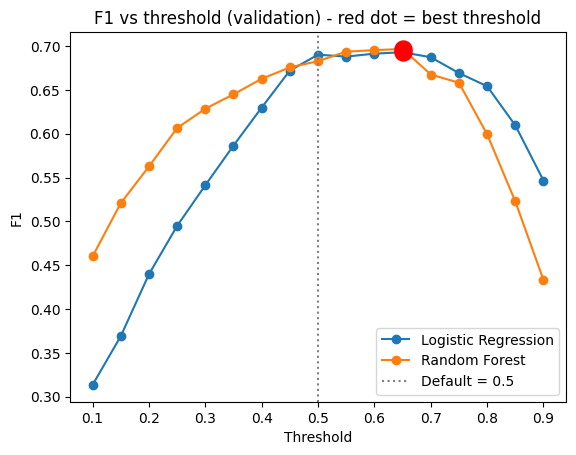

,pr_auc,roc_auc,best_threshold,best_f1
model,,,,
Logistic Regression,0.687,0.923,0.65,0.693
Random Forest,0.737,0.934,0.65,0.697


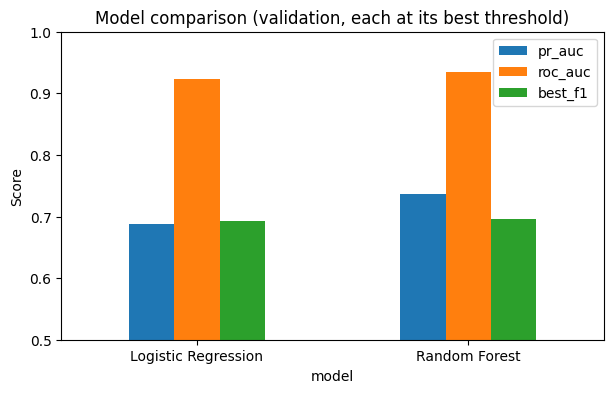

In [ ]:
from sklearn.metrics import roc_auc_score

thresholds = np.arange(0.10, 0.91, 0.05)
summary = []

# TODO: Graph 1 - F1 vs threshold for both models
for name, model in [("Logistic Regression", best_lr), ("Random Forest", best_rf)]:
    proba = model.predict_proba(X_val)[:, 1]
    f1s = [f1_score(y_val, (proba >= t).astype(int)) for t in thresholds]
    i = int(np.argmax(f1s))

    plt.plot(thresholds, f1s, marker="o", label=name)
    plt.scatter(thresholds[i], f1s[i], s=150, color="red", zorder=3)

    summary.append({
        "model": name,
        "pr_auc": average_precision_score(y_val, proba),
        "roc_auc": roc_auc_score(y_val, proba),
        "best_threshold": round(thresholds[i], 2),
        "best_f1": f1s[i],
    })

plt.axvline(0.5, color="gray", linestyle=":", label="Default = 0.5")
plt.xlabel("Threshold")
plt.ylabel("F1")
plt.title("F1 vs threshold (validation) - red dot = best threshold")
plt.legend()
plt.show()

# TODO: table of results
summary_df = pd.DataFrame(summary).set_index("model")
display(summary_df.round(3))

# TODO: Graph 2 - bar chart of the three scores
summary_df[["pr_auc", "roc_auc", "best_f1"]].plot(kind="bar", figsize=(7, 4))
plt.ylim(0.5, 1.0)
plt.ylabel("Score")
plt.title("Model comparison (validation, each at its best threshold)")
plt.xticks(rotation=0)
plt.show()

**Result:**

| Model | PR-AUC | ROC-AUC | Best threshold | Best F1 |
|---|---|---|---|---|
| Logistic Regression | 0.687 | 0.923 | 0.65 | 0.693 |
| Random Forest | **0.737** | **0.934** | 0.65 | **0.697** |

- **Random Forest is better on both threshold-free metrics**: PR-AUC (+0.05) and ROC-AUC (+0.011). This confirms the choice made in 5.4.
- **At their best thresholds, the two models have almost the same F1** (0.697 vs 0.693). Random Forest's advantage is therefore not at one single threshold, but across the full range of thresholds.
- **The F1 curves show where each model is stronger:** Random Forest is clearly better at low thresholds (below 0.45), where the goal is to catch nearly all buyers; the two are similar between 0.45 and 0.65; Logistic Regression is slightly better above 0.7.
- The two models produce probabilities differently (Random Forest: share of tree votes; Logistic Regression: a fitted formula), so the same threshold value does not mean the same thing for both. This is why a fixed-threshold comparison can mislead and PR-AUC is used as the main metric.
- ROC-AUC is high for both models (above 0.92) because it also rewards correctly rejecting the many non-buyers; PR-AUC, which focuses on the buyer class, shows the gap more clearly.

**Final model choice: Random Forest**, with Logistic Regression kept as an interpretable reference.

## 6. Threshold Analysis (Random Forest)
### 6.1 Choose the threshold on the validation set
The model outputs a **probability** of purchase for each session. A **threshold** turns it into a yes/no decision: if probability ≥ threshold, predict "purchase".

- **Lower threshold** → more sessions predicted as purchase → catches more buyers (**higher recall**) but more false alarms (**lower precision**).
- **Higher threshold** → fewer, more confident predictions → **higher precision**, **lower recall**.

The default of 0.5 is not necessarily best for imbalanced data. Thresholds from 0.10 to 0.90 are tested on the **validation set**, and the threshold with the **highest F1** (best balance of precision and recall) is chosen. The test set is not used here.

Best threshold (highest F1): 0.65


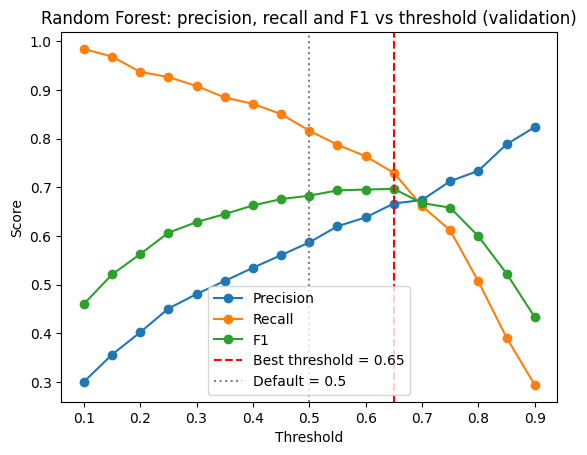

,threshold,precision,recall,f1
0,0.10,0.300,0.984,0.460
1,0.15,0.356,0.969,0.521
2,0.20,0.402,0.937,0.563
3,0.25,0.451,0.927,0.607
4,0.30,0.481,0.908,0.629
5,0.35,0.508,0.885,0.645
6,0.40,0.535,0.871,0.663
7,0.45,0.561,0.850,0.676
8,0.50,0.587,0.816,0.683
9,0.55,0.620,0.787,0.694


In [ ]:
# TODO: probability of purchase for each validation session
proba_val = best_rf.predict_proba(X_val)[:, 1]

# TODO: try thresholds from 0.10 to 0.90
thresholds = np.arange(0.10, 0.91, 0.05)
rows = []
for t in thresholds:
    pred = (proba_val >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall":    recall_score(y_val, pred),
        "f1":        f1_score(y_val, pred),
    })
thr_df = pd.DataFrame(rows)

# TODO: pick the threshold with the highest F1
best_t = thr_df.loc[thr_df["f1"].idxmax(), "threshold"]
print("Best threshold (highest F1):", best_t)

# TODO: plot precision, recall and F1 against the threshold
plt.plot(thr_df["threshold"], thr_df["precision"], marker="o", label="Precision")
plt.plot(thr_df["threshold"], thr_df["recall"], marker="o", label="Recall")
plt.plot(thr_df["threshold"], thr_df["f1"], marker="o", label="F1")
plt.axvline(best_t, color="red", linestyle="--", label=f"Best threshold = {best_t}")
plt.axvline(0.5, color="gray", linestyle=":", label="Default = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Random Forest: precision, recall and F1 vs threshold (validation)")
plt.legend()
plt.show()

thr_df.round(3)

### 6.2 Effect of the threshold in real numbers
Confusion matrices at the default threshold (0.5) and the chosen threshold (0.65), to show how many buyers are caught or missed and how many false alarms each produces.

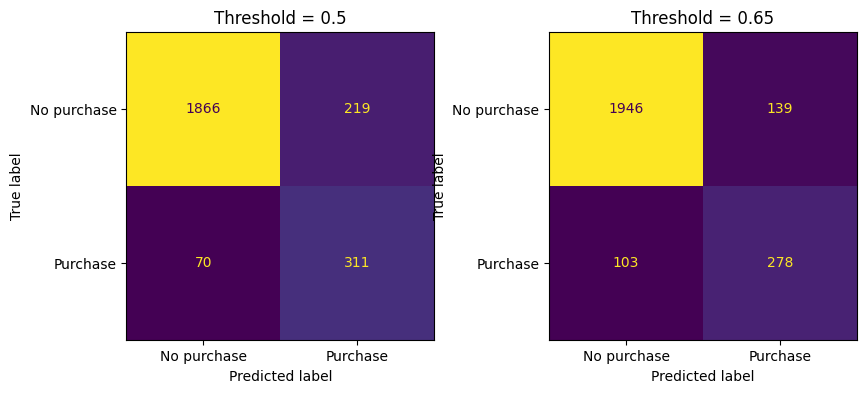

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# TODO: confusion matrix at the default and the best threshold
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, t in zip(axes, [0.5, best_t]):
    pred = (proba_val >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_val, pred, display_labels=["No purchase", "Purchase"], ax=ax, colorbar=False)
    ax.set_title(f"Threshold = {t}")
plt.show()

**Result: the chosen threshold is 0.65** (F1 = 0.697, compared with 0.683 at the default of 0.5).

**What the threshold graph shows:**
- As the threshold increases, **precision rises** and **recall falls**: being stricter gives fewer false alarms but misses more buyers.
- **F1 peaks at 0.65.** The peak is fairly flat (F1 = 0.694–0.697 between 0.55 and 0.65), then drops quickly above 0.70 as recall falls sharply.
- At very low thresholds (0.10), the model catches 98% of buyers, but only 30% of its predicted purchases are real.

**The trade-off in numbers (validation set, 381 buyers):**

| | Threshold 0.5 | Threshold 0.65 | Change |
|---|---|---|---|
| Buyers caught | 311 | 278 | −33 |
| Buyers missed | 70 | 103 | +33 |
| False alarms | 219 | 139 | **−80** |
| Precision | 0.587 | 0.667 | +0.080 |
| Recall | 0.816 | 0.730 | −0.086 |

Raising the threshold from 0.5 to 0.65 gives up **33 buyers** to remove **80 false alarms**, a 37% reduction. Out of every 3 sessions the model flags as a purchase, about 2 are now real buyers (precision 0.667), compared with fewer than 6 in 10 at 0.5.

**Choice of threshold:** 0.65 is used for the final test evaluation, because it maximises F1, which weighs precision and recall equally. In practice the best threshold depends on costs:
- If **missing a buyer is costly** (for example, a lost chance to offer a discount), a lower threshold (0.4–0.5) is better.
- If **false alarms are costly** (for example, offering discounts to people who would never buy), a higher threshold (0.7+) is better.

This directly answers the research question: the classification threshold controls the balance between identifying purchasing sessions and limiting false positives.

## 7. Feature importance analysis

**Goal:** find out which features drive the purchase prediction (research question, part 1).

All checks in this section use the **validation set**. The test set is still untouched.

### 7.0 PCA check (dimensionality reduction)

**How PCA works:**
1. Scale the features (done by our preprocessor).
2. Compute the covariance matrix of the 66 processed columns.
3. Find its **eigenvectors** (new directions) and **eigenvalues** (variance along each direction).
4. Sort by eigenvalue and keep the top *k* components.
5. Project the data onto these *k* directions, so each session becomes *k* numbers instead of 66.

**What is a component?** Each component is a *new column* made from a weighted mix of all 66 processed columns.
It is not one of the original features.

**Assumption:** we keep enough components to explain **90% of the variance** (a common rule of thumb).
`explained_variance_ratio_` = each eigenvalue ÷ sum of all eigenvalues; the cumulative sum tells us how many components we need.

**Test:** retrain the best LR and best RF on k = 5, 10, 20, 30 components and compare validation PR-AUC with "No PCA".

Components for 90% variance: 19
Components for 95% variance: 27
Variance explained by the first component: 0.319


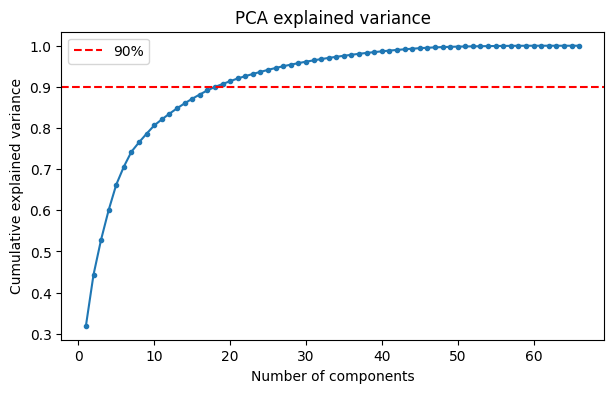

                 model components  pr_auc
0  Logistic Regression     No PCA   0.687
1  Logistic Regression          5   0.665
2  Logistic Regression         10   0.677
3  Logistic Regression         20   0.685
4  Logistic Regression         30   0.686
5        Random Forest     No PCA   0.737
6        Random Forest          5   0.686
7        Random Forest         10   0.712
8        Random Forest         20   0.720
9        Random Forest         30   0.716


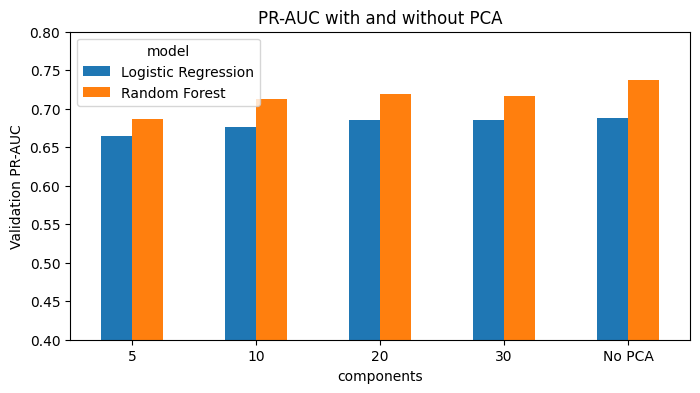

In [ ]:
# TODO: 7.0 PCA check
from sklearn.decomposition import PCA
from sklearn.base import clone

# fit PCA on the processed training data to see the explained variance
pca_full = Pipeline([("prep", make_preprocessor()), ("pca", PCA())]).fit(X_train)
cum_var = np.cumsum(pca_full.named_steps["pca"].explained_variance_ratio_)

print("Components for 90% variance:", np.argmax(cum_var >= 0.90) + 1)
print("Components for 95% variance:", np.argmax(cum_var >= 0.95) + 1)
print("Variance explained by the first component:", round(pca_full.named_steps["pca"].explained_variance_ratio_[0], 3))

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker=".")
plt.axhline(0.90, color="red", linestyle="--", label="90%")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance")
plt.legend()
plt.show()

# retrain both best models on k components and compare PR-AUC
rows = []
for name, best in [("Logistic Regression", best_lr), ("Random Forest", best_rf)]:
    rows.append({"model": name, "components": "No PCA",
                 "pr_auc": average_precision_score(y_val, best.predict_proba(X_val)[:, 1])})
    for k in [5, 10, 20, 30]:
        pca_model = Pipeline([("prep", make_preprocessor()),
                              ("pca", PCA(n_components=k, random_state=RANDOM_STATE)),
                              ("model", clone(best.named_steps["model"]))])
        pca_model.fit(X_train, y_train)
        rows.append({"model": name, "components": k,
                     "pr_auc": average_precision_score(y_val, pca_model.predict_proba(X_val)[:, 1])})

pca_df = pd.DataFrame(rows)
print(pca_df.round(3))

pca_df.pivot(index="components", columns="model", values="pr_auc").plot(kind="bar", figsize=(8, 4))
plt.ylabel("Validation PR-AUC")
plt.ylim(0.4, 0.8)
plt.title("PR-AUC with and without PCA")
plt.xticks(rotation=0)
plt.show()

**Result (7.0):**

- **90% of the variance** needs **19 components** and 95% needs **27** (out of 66 processed columns).
- The first component alone explains about 32% of the variance. After about 20 components the curve flattens, so each extra component adds very little.

| Components | LR PR-AUC | RF PR-AUC |
|---|---|---|
| 5 | 0.665 | 0.686 |
| 10 | 0.677 | 0.712 |
| 20 | 0.685 | 0.720 |
| 30 | 0.686 | 0.716 |
| **No PCA** | **0.687** | **0.737** |

**Observations:**
- PCA **never improves** either model. The best score is always "No PCA".
- **Logistic Regression** hardly changes from 20 components onwards (0.685–0.686 vs 0.687), so PCA neither helps nor hurts it much.
- **Random Forest** loses more: even its best PCA score (0.720 with 20 components) is **0.017 below** No PCA, and with 5 components it drops by 0.051.
  RF splits on one feature at a time. PCA mixes all features into each component, so RF can no longer split cleanly on a strong feature like PageValues.
- Keeping 90% of the variance (19 components) still costs RF about 0.02 PR-AUC. **High variance ≠ high predictive power.**

**Decision:** we **do not use PCA**. It lowers performance (mainly for RF), and each component mixes all features,
so we could no longer say *which feature* matters, which is our research question.
We use **permutation importance** and **feature ablation** instead.

### 7.1 Permutation importance (Random Forest)

**Question:** if we scramble one feature, how much worse does the model get?

**How it works:**
1. Take the **already-trained** best Random Forest (it is not retrained).
2. Score it on the validation set as normal → PR-AUC ≈ 0.737.
3. Pick **one feature** and **shuffle its column randomly** across the validation rows. All other features stay the same.
4. Score the model again and measure **how much PR-AUC dropped**.
5. Put the feature back and repeat for the next feature.

**Why shuffling works:** the column keeps the same values (same distribution), but the link between that feature and `Revenue` is broken.
For example, a buyer may now get a non-buyer's PageValues.
- Model relied on the feature → predictions get worse → **big drop** → **important**
- Model ignored the feature → predictions don't change → **drop ≈ 0** → **not important**

**Setup:**
| Choice | Reason |
|---|---|
| All **17 original features**, one at a time | Each drop belongs to that feature alone |
| Shuffled on **original features**, not the 66 encoded columns | The pipeline encodes after shuffling, so e.g. all of `Month` is shuffled together, which is easier to interpret |
| **Validation set** | We want what matters for new data, not what the model memorised in training |
| **10 shuffles per feature** (`n_repeats=10`) | One shuffle could be lucky or unlucky; we report the **mean drop ± std** (17 × 10 = 170 scorings) |
| Scored by **PR-AUC** | The same metric we used to select the model |
| **Random Forest** | Our chosen model (LR is checked separately in 7.2) |

**Difference from ablation (7.3):** here the model is *not retrained*, so this shows how much *this model* relies on each feature.
Ablation retrains without a feature group to see whether other features can make up for it.

                feature  importance    std
             PageValues      0.5310 0.0090
              ExitRates      0.0443 0.0138
                  Month      0.0413 0.0039
            BounceRates      0.0343 0.0117
         ProductRelated      0.0187 0.0045
         Administrative      0.0184 0.0069
ProductRelated_Duration      0.0088 0.0045
Administrative_Duration      0.0033 0.0029
                 Region      0.0017 0.0014
       OperatingSystems      0.0007 0.0008
                Browser      0.0004 0.0011
          Informational      0.0001 0.0012
                Weekend     -0.0001 0.0004
             SpecialDay     -0.0003 0.0013
 Informational_Duration     -0.0006 0.0024
            VisitorType     -0.0009 0.0012
            TrafficType     -0.0022 0.0028


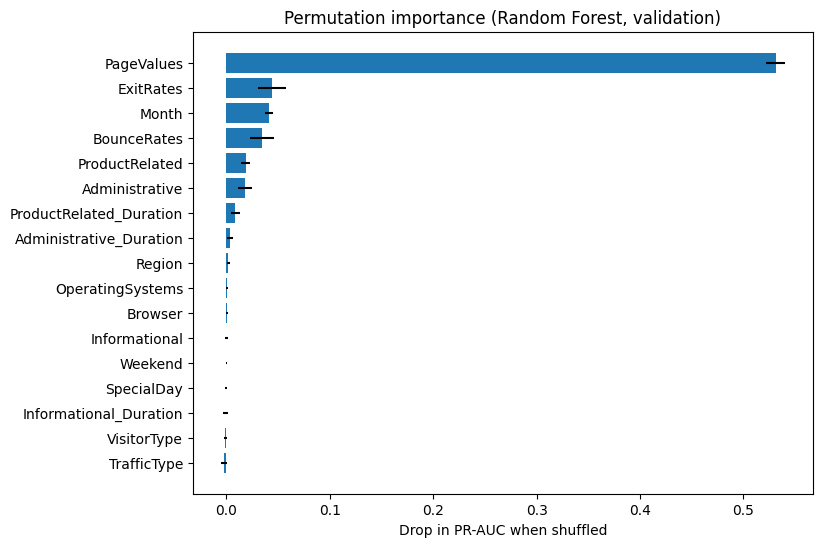

In [ ]:
# TODO: 7.1 Permutation importance on validation set (all 17 features)
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_rf, X_val, y_val, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)

imp_df = pd.DataFrame({"feature": X_val.columns,
                       "importance": perm.importances_mean,
                       "std": perm.importances_std}).sort_values("importance", ascending=False)
print(imp_df.round(4).to_string(index=False))

plt.figure(figsize=(8, 6))
plt.barh(imp_df["feature"], imp_df["importance"], xerr=imp_df["std"])
plt.gca().invert_yaxis()
plt.xlabel("Drop in PR-AUC when shuffled")
plt.title("Permutation importance (Random Forest, validation)")
plt.show()

**Result (7.1):**

| Rank | Feature | PR-AUC drop (mean ± std) | Level |
|---|---|---|---|
| 1 | PageValues | **0.531 ± 0.009** | Dominant |
| 2 | ExitRates | 0.044 ± 0.014 | Moderate |
| 3 | Month | 0.041 ± 0.004 | Moderate |
| 4 | BounceRates | 0.034 ± 0.012 | Moderate |
| 5 | ProductRelated | 0.019 ± 0.005 | Small |
| 6 | Administrative | 0.018 ± 0.007 | Small |
| 7 | ProductRelated_Duration | 0.009 ± 0.005 | Small |
| 8 | Administrative_Duration | 0.003 ± 0.003 | ≈ 0 |
| 9–17 | Region, OperatingSystems, Browser, Informational, Weekend, SpecialDay, Informational_Duration, VisitorType, TrafficType | between −0.002 and +0.002 | ≈ 0 |

**Observations:**
- **PageValues dominates.** Shuffling it drops PR-AUC from 0.737 to about 0.21, roughly **12× more** than the next feature.
  The model relies on it far more than on anything else.
- **ExitRates, Month and BounceRates** form a second tier (drops of about 0.03–0.04).
  ExitRates and Month are almost tied; their error bars overlap, so their order is not certain.
- **Page counts** (ProductRelated, Administrative) help a little (about 0.02).
- **9 features have no effect** (drop ≈ 0). Small negative values (e.g. TrafficType −0.002) are smaller than their std, so they are just random noise from shuffling, not a real negative effect.
  These include all the **technical/visitor codes** (Browser, OperatingSystems, Region, TrafficType, VisitorType), the **Informational** pages, **Weekend** and **SpecialDay**.

**Note:** ExitRates and BounceRates are strongly related. When one is shuffled, the model can partly use the other,
so permutation importance may **underestimate** both. Ablation (7.3) removes them together as a group to check this.

### 7.2 Logistic Regression coefficients

**Question:** does a *different* model agree with Random Forest about which features matter, and in which *direction* do they push the prediction?

**Why we do this:**
1. **Second opinion:** Random Forest (trees) and Logistic Regression (a weighted sum) work in very different ways.
   If both point to the same top features, the finding is much more trustworthy than from one model alone.
2. **Direction of the effect:** permutation importance (7.1) only tells us *how much* a feature matters.
   Coefficients also tell us *which way*. For example, does November increase or decrease buying?

**How Logistic Regression uses features:**
LR gives each processed column a weight (coefficient) and adds them up:

score = w₁ × PageValues + w₂ × ExitRates + w₃ × Month_Nov + … (66 columns)

The score is then turned into a buying probability between 0 and 1.

**How to read a coefficient:**
| Coefficient | Meaning |
|---|---|
| Positive (e.g. +1.3) | Higher value → **more** likely to buy |
| Negative (e.g. −0.3) | Higher value → **less** likely to buy |
| Close to 0 | The feature barely matters |
| Larger size (ignoring the sign) | Stronger effect |

**Why the coefficients can be compared:** all numeric features were **scaled** (mean 0, std 1) by our preprocessor,
so they are on the same scale. Without scaling, a feature measured in seconds would get a tiny weight just because its numbers are large.

**How we do it:**
1. Take the 66 coefficients from the best LR model (C = 0.01) and the 66 column names from the preprocessor.
2. Sort them by absolute size and keep the **top 15**.
3. Plot them: **green = increases buying**, **red = decreases buying**.

**Notes:**
- LR works on the **66 encoded columns**, so `Month` is split into `Month_Nov`, `Month_May`, and so on. This lets us see *which* month matters.
- A one-hot coefficient is read **relative to the other categories** of the same feature (e.g. November compared with the other months).
- C = 0.01 means strong regularisation, which shrinks all coefficients toward 0. So we compare their **relative sizes**, not the exact values.
- Coefficients show *association*, not *cause*: November sessions buy more, but November itself may not be the cause.

                      feature   coef  abs_coef
                   PageValues  1.326     1.326
                    Month_Nov  0.671     0.671
                    Month_May -0.457     0.457
                    Month_Mar -0.318     0.318
                    ExitRates -0.281     0.281
                TrafficType_1 -0.256     0.256
                TrafficType_8  0.225     0.225
                TrafficType_3 -0.188     0.188
                  BounceRates -0.181     0.181
      VisitorType_New_Visitor  0.177     0.177
VisitorType_Returning_Visitor -0.175     0.175
                    Month_Dec -0.165     0.165
               TrafficType_13 -0.164     0.164
               ProductRelated  0.164     0.164
                TrafficType_5  0.150     0.150


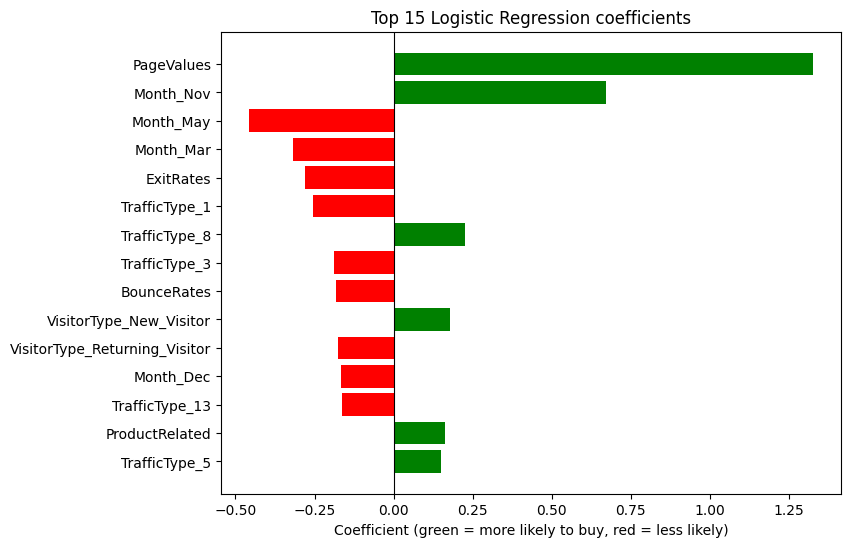

In [ ]:
# TODO: 7.2 LR coefficients (top 15 by size)
coef_df = pd.DataFrame({"feature": best_lr.named_steps["prep"].get_feature_names_out(),
                        "coef": best_lr.named_steps["model"].coef_[0]})
coef_df["abs_coef"] = coef_df["coef"].abs()
top_coef = coef_df.sort_values("abs_coef", ascending=False).head(15)
print(top_coef.round(3).to_string(index=False))

colors = ["green" if c > 0 else "red" for c in top_coef["coef"]]
plt.figure(figsize=(8, 6))
plt.barh(top_coef["feature"], top_coef["coef"], color=colors)
plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (green = more likely to buy, red = less likely)")
plt.title("Top 15 Logistic Regression coefficients")
plt.show()

**Result (7.2):**

| Rank | Column | Coefficient | Direction |
|---|---|---|---|
| 1 | PageValues | **+1.326** | ↑ more likely to buy |
| 2 | Month_Nov | +0.671 | ↑ |
| 3 | Month_May | −0.457 | ↓ less likely to buy |
| 4 | Month_Mar | −0.318 | ↓ |
| 5 | ExitRates | −0.281 | ↓ |
| 6 | TrafficType_1 | −0.256 | ↓ |
| 7 | TrafficType_8 | +0.225 | ↑ |
| 8 | TrafficType_3 | −0.188 | ↓ |
| 9 | BounceRates | −0.181 | ↓ |
| 10 | VisitorType_New_Visitor | +0.177 | ↑ |
| 11 | VisitorType_Returning_Visitor | −0.175 | ↓ |
| 12 | Month_Dec | −0.165 | ↓ |
| 13 | TrafficType_13 | −0.164 | ↓ |
| 14 | ProductRelated | +0.164 | ↑ |
| 15 | TrafficType_5 | +0.150 | ↑ |

**Observations:**
- **PageValues** has by far the largest coefficient (+1.33, about 2× the next one). Sessions that visit high-value pages are much more likely to buy.
- **Month:** November strongly increases buying (+0.67), while May, March and December decrease it.
  This matches the EDA: November is the peak shopping month. December is lower than expected, possibly because most purchases happen before the holidays.
- **ExitRates (−0.28) and BounceRates (−0.18)** are negative. Visitors who leave pages quickly rarely buy.
- **ProductRelated (+0.16)** is positive. Viewing more product pages slightly increases buying.
- **New visitors** are slightly more likely to buy than returning ones (+0.18 vs −0.18).

**Comparison with Random Forest permutation importance (7.1):**

| Feature | RF permutation (7.1) | LR coefficient (7.2) | Agree? |
|---|---|---|---|
| PageValues | #1 (0.531) | #1 (+1.33) | ✅ Yes |
| ExitRates / BounceRates | #2, #4 | Negative, top 9 | ✅ Yes |
| Month | #3 | Nov / May / Mar in top 4 | ✅ Yes |
| ProductRelated | #5 | +0.16 | ✅ Yes |
| TrafficType | ≈ 0 (last place) | Several codes in top 15 | ❌ No |
| VisitorType | ≈ 0 | ±0.18 | ❌ No |

- **Both models agree on the main drivers:** PageValues → exit/bounce behaviour → Month → product page counts.
  Two very different models give the same ranking, so we trust this result.
- **They disagree on TrafficType and VisitorType.** LR gives weight to some individual codes, but RF gains nothing from them.
  These effects are small (each below 0.26) and spread over many categories, so they are probably weak or unstable patterns.
  The ablation in 7.3 checks whether removing the visitor/tech group actually hurts performance.

### 7.3 Feature-group ablation (all combinations)

**Question:** which groups of features does the model actually *need*?

**What ablation is:** we **remove** groups of features completely, **retrain** a new Random Forest (same best settings: depth 10, max_features 0.5, leaf 5)
on only the remaining features, and compare validation PR-AUC with the full model.
- Big drop → the removed group carries information nothing else can replace
- Small / no drop → the group is not needed, or other features already cover it

**Difference from permutation importance (7.1):** permutation *shuffles* one feature without retraining (what this model relies on).
Ablation *removes* features and *retrains* (whether the model can do as well without them).
This matters for related features like ExitRates and BounceRates, which can cover for each other.

**Groups (N = 5):**
| Group | Features | Count |
|---|---|---|
| page_behaviour | Administrative, Informational, ProductRelated + their durations | 6 |
| engagement | BounceRates, ExitRates | 2 |
| page_value | PageValues | 1 |
| time_context | Month, SpecialDay, Weekend | 3 |
| visitor_tech | VisitorType, OperatingSystems, Browser, Region, TrafficType | 5 |

**Why PageValues is its own group:** PageValues was flagged as a possible **leakage** feature *before* running any experiments.
It is calculated from pages that lead to a purchase, so it may partly contain the answer.
Making it a separate group lets us add and remove it in **every** combination and measure its effect on its own.
The other groups follow Section 4.1 (grouped by what the features describe).

**Why all combinations (N choose k):** we keep k groups for every k = 1 … 5:
C(5,1) + C(5,2) + C(5,3) + C(5,4) + C(5,5) = 5 + 10 + 10 + 5 + 1 = **31 models**.
- k = 1: what each group can do **alone** (includes "PageValues only")
- k = 2, 3: how groups **add to / overlap with** each other
- k = 4: the full model **minus one group** (classic ablation, includes "without PageValues")
- k = 5: all groups = the **full model** (reference)

k is the number of groups we **keep and train on**. Choosing k to keep = choosing 5 − k to remove, since C(N, k) = C(N, N − k).

**Why not all subsets of the 17 single features?** That would be 2¹⁷ − 1 = 131,071 models, far too slow.
With so many models, some would also score high by luck, which overfits the validation set.

**How we read the results:**
- `change` = combination PR-AUC − full model PR-AUC
- A drop larger than 0.02 is meaningful (same rule as in model selection); within ±0.01 is noise
- Compare with the **baseline 0.155** (share of buyers) to see whether a weak model is still better than guessing
- These results are **analysis only**. We keep the full model for the final test, so we don't pick a subset just because it scored best on validation.

Full model PR-AUC: 0.737   Baseline (buyer share): 0.155

                                                                    groups  k  n_features  has_PageValues  pr_auc  change
0                  page_behaviour + engagement + page_value + time_context  4          12            True   0.739   0.002
1   page_behaviour + engagement + page_value + time_context + visitor_tech  5          17            True   0.737   0.000
2                    engagement + page_value + time_context + visitor_tech  4          11            True   0.733  -0.004
3                  page_behaviour + engagement + page_value + visitor_tech  4          14            True   0.715  -0.022
4                                   engagement + page_value + time_context  3           6            True   0.714  -0.023
5                                 page_behaviour + engagement + page_value  3           9            True   0.709  -0.028
6                page_behaviour + page_value + time_context + visitor_tech  4          1

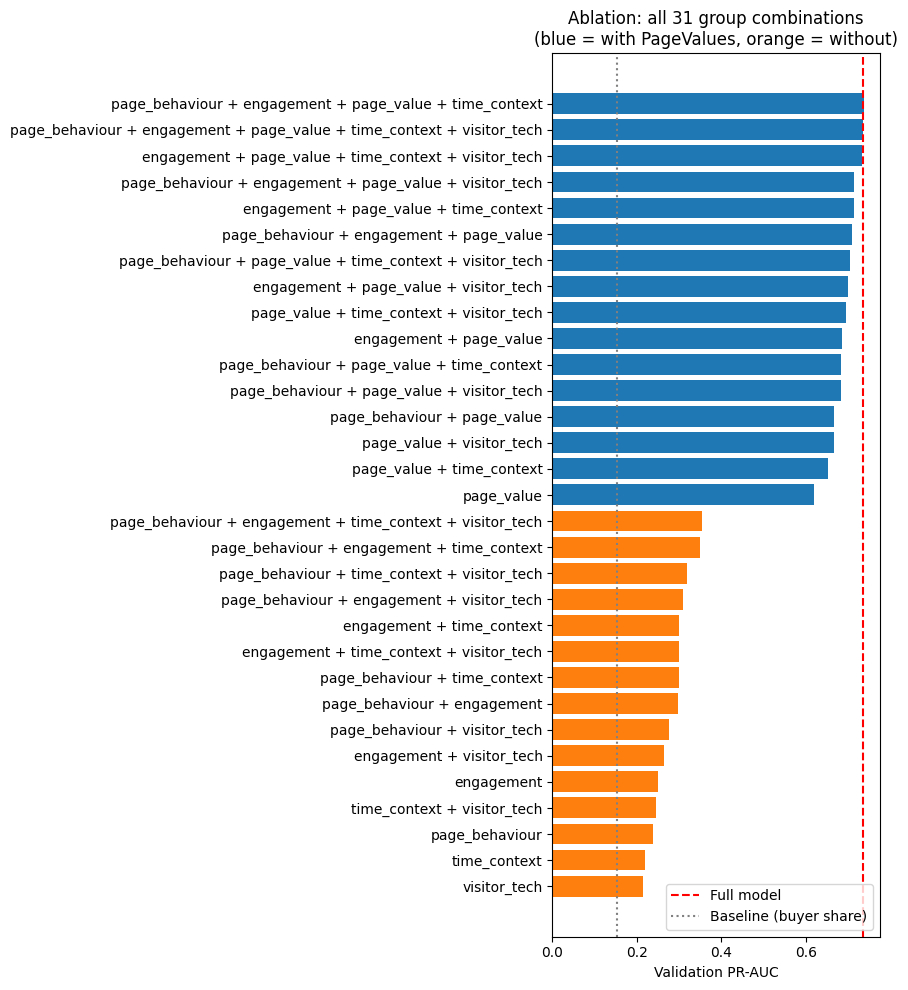

In [ ]:
# TODO: 7.3 Ablation: retrain RF on every combination of the 5 feature groups
from itertools import combinations

ablation_groups = {
    "page_behaviour": page_behaviour,
    "engagement": ["BounceRates", "ExitRates"],
    "page_value": ["PageValues"],
    "time_context": time_context,
    "visitor_tech": visitor_tech,
}
group_names = list(ablation_groups.keys())

rows = []
for k in range(1, len(group_names) + 1):
    for combo in combinations(group_names, k):
        feats = []
        for g in combo:
            feats += ablation_groups[g]
        model = Pipeline([("prep", make_preprocessor(feats)),
                          ("model", clone(best_rf.named_steps["model"]))])
        model.fit(X_train, y_train)
        pr_auc = average_precision_score(y_val, model.predict_proba(X_val)[:, 1])
        rows.append({"groups": " + ".join(combo), "k": k, "n_features": len(feats),
                     "has_PageValues": "page_value" in combo, "pr_auc": pr_auc})

ablation_df = pd.DataFrame(rows).sort_values("pr_auc", ascending=False).reset_index(drop=True)
full_score = ablation_df.loc[ablation_df["k"] == 5, "pr_auc"].iloc[0]
ablation_df["change"] = ablation_df["pr_auc"] - full_score
print(f"Full model PR-AUC: {full_score:.3f}   Baseline (buyer share): {y_val.mean():.3f}\n")
print(ablation_df.round(3).to_string())

colors = ["tab:blue" if pv else "tab:orange" for pv in ablation_df["has_PageValues"]]
plt.figure(figsize=(9, 10))
plt.barh(ablation_df["groups"], ablation_df["pr_auc"], color=colors)
plt.axvline(full_score, color="red", linestyle="--", label="Full model")
plt.axvline(y_val.mean(), color="gray", linestyle=":", label="Baseline (buyer share)")
plt.gca().invert_yaxis()
plt.xlabel("Validation PR-AUC")
plt.title("Ablation: all 31 group combinations\n(blue = with PageValues, orange = without)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Result (7.3):** Full model PR-AUC = **0.737**, baseline (buyer share) = **0.155**

**1. Removing one group (k = 4, classic ablation):**
| Group removed | PR-AUC | Change | Meaning |
|---|---|---|---|
| visitor_tech | 0.739 | +0.002 | Not needed (noise) |
| page_behaviour | 0.733 | −0.004 | Not needed (noise) |
| time_context | 0.715 | −0.022 | Small but real loss |
| engagement (Bounce + Exit) | 0.704 | −0.033 | Real loss |
| **page_value** | **0.355** | **−0.382** | **Huge loss** |

**2. Each group alone (k = 1):**
| Group | Features | PR-AUC |
|---|---|---|
| **page_value** | 1 | **0.620** |
| engagement | 2 | 0.249 |
| page_behaviour | 6 | 0.238 |
| time_context | 3 | 0.221 |
| visitor_tech | 5 | 0.214 |

**Observations:**
- **The chart splits cleanly into two blocks.** *Every* combination with PageValues (blue, 0.620–0.739)
  beats *every* combination without it (orange, 0.214–0.355). Even **PageValues alone** (0.620) is far better than the best model without it (0.355).
- **PageValues alone gives 84% of the full model's score** (0.620 / 0.737) from just 1 of 17 features.
- **engagement (Bounce/Exit) and time_context (Month)** add real value on top of PageValues (−0.033 and −0.022 when removed).
  This agrees with permutation importance (7.1) and the LR coefficients (7.2).
- **page_behaviour and visitor_tech can be removed with no loss** (changes within ±0.005, i.e. noise).
  page_behaviour overlaps with PageValues and engagement, and visitor_tech carries almost no signal.
  This settles the LR vs RF disagreement from 7.2: the TrafficType/VisitorType coefficients do not translate into better predictions.
- **A small model is almost as good:** engagement + page_value + time_context (**6 features**) reaches **0.714**,
  about 97% of the full model with about a third of the features.

**Dependence on PageValues:**
- Removing only PageValues drops PR-AUC from **0.737 to 0.355**, roughly **half** (−52%).
- Measured above the baseline (0.355 − 0.155 = 0.200 vs 0.737 − 0.155 = 0.582), the model keeps only about **one third** of its useful predictive power.
- Without PageValues the model is still about **2.3× the baseline**, so the other features carry some real signal.

**Decision:** we keep the **full model** (all 17 features) for the final test.
The best score (0.739, without visitor_tech) is only +0.002 above the full model, which is noise, and choosing it from 31 tries would overfit the validation set.

*The meaning of this result for real-world use (leakage and real-time prediction) is discussed in Section 9.4.*

### 7.4 Top-k feature curve

**Question:** how many features does the model actually need?

**How it works:**
1. Take the feature ranking from **7.1 permutation importance** (most important first).
2. Train the Random Forest (same best settings) on only the **top 1** feature, then the **top 2**, top 3, …, up to all 17.
3. Score each model on validation (PR-AUC) and plot PR-AUC against k (number of features).

| k | Features used |
|---|---|
| 1 | PageValues |
| 2 | PageValues + ExitRates |
| 3 | PageValues + ExitRates + Month |
| … | … |
| 17 | all features (full model) |

This needs only **17 models** (one per k), instead of trying all 2¹⁷ − 1 = 131,071 subsets.
**k is chosen by the curve, not by us:** the point where the curve flattens shows how many features are enough.

**Difference from 7.3:** 7.3 removed whole *groups*; here we add *single features* in order of importance.
This shows whether a few top features are enough, even if their groups also contain useless features (e.g. Weekend in time_context).

**Caveats:**
- The ranking comes from the validation set, and we score on validation again, so the curve is **slightly optimistic**.
  It is used for **analysis only**; the final model keeps all features.
- Features are added in one fixed order; a different order could flatten a little earlier or later.
- Small ups and downs (about ±0.005) after the curve flattens are noise.

 k           added_feature  pr_auc
 1              PageValues   0.620
 2               ExitRates   0.682
 3                   Month   0.699
 4             BounceRates   0.713
 5          ProductRelated   0.742
 6          Administrative   0.755
 7 ProductRelated_Duration   0.745
 8 Administrative_Duration   0.741
 9                  Region   0.743
10        OperatingSystems   0.741
11                 Browser   0.744
12           Informational   0.741
13                 Weekend   0.743
14              SpecialDay   0.745
15  Informational_Duration   0.735
16             VisitorType   0.738
17             TrafficType   0.737


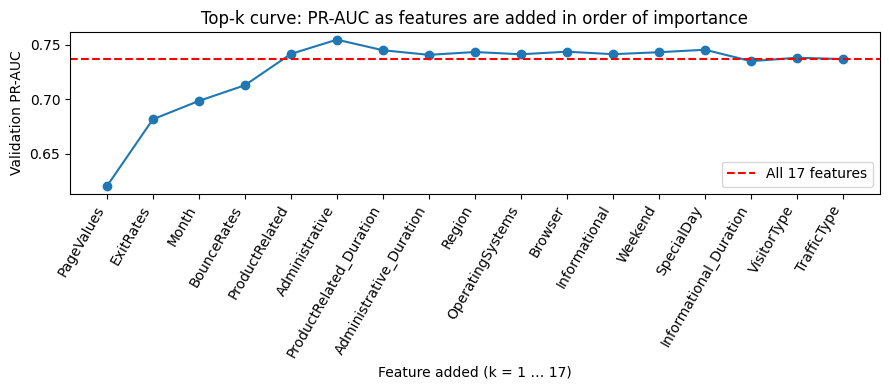

In [ ]:
# TODO: 7.4 Top-k curve: add features one at a time in permutation-importance order
ranked_features = list(imp_df["feature"])   # ranking from 7.1, most important first

rows = []
for k in range(1, len(ranked_features) + 1):
    feats = ranked_features[:k]
    model = Pipeline([("prep", make_preprocessor(feats)),
                      ("model", clone(best_rf.named_steps["model"]))])
    model.fit(X_train, y_train)
    pr_auc = average_precision_score(y_val, model.predict_proba(X_val)[:, 1])
    rows.append({"k": k, "added_feature": feats[-1], "pr_auc": pr_auc})

topk_df = pd.DataFrame(rows)
print(topk_df.round(3).to_string(index=False))

plt.figure(figsize=(9, 4))
plt.plot(topk_df["k"], topk_df["pr_auc"], marker="o")
plt.axhline(topk_df["pr_auc"].iloc[-1], color="red", linestyle="--", label="All 17 features")
plt.xticks(topk_df["k"], topk_df["added_feature"], rotation=60, ha="right")
plt.xlabel("Feature added (k = 1 … 17)")
plt.ylabel("Validation PR-AUC")
plt.title("Top-k curve: PR-AUC as features are added in order of importance")
plt.legend()
plt.tight_layout()
plt.show()

**Result (7.4):**

| k | Feature added | PR-AUC | Gain from adding it |
|---|---|---|---|
| 1 | PageValues | 0.620 | – |
| 2 | ExitRates | 0.682 | +0.062 |
| 3 | Month | 0.699 | +0.017 |
| 4 | BounceRates | 0.713 | +0.014 |
| 5 | ProductRelated | 0.742 | +0.029 |
| 6 | Administrative | **0.755** | +0.013 (highest point) |
| 7–17 | the remaining 11 features | 0.735 – 0.745 | flat (noise) |
| 17 | all features | 0.737 | (full model) |

**Observations:**
- **The curve rises up to k = 5–6 and then goes flat.** With just the **top 5 features**
  (PageValues, ExitRates, Month, BounceRates, ProductRelated), PR-AUC (0.742) already matches the full model (0.737).
- **The other 11 features add nothing:** after k = 6 the score just moves up and down between 0.735 and 0.745, which is noise.
  This agrees with 7.1 (their permutation importance ≈ 0) and 7.3 (visitor_tech can be removed without loss).
- **Biggest single gain after PageValues: ExitRates (+0.062).** Knowing how often visitors leave adds the most on top of page value.
- **Page counts (ProductRelated, Administrative) help when few features are present** (+0.029, +0.013),
  but in 7.3 removing page_behaviour from the full model cost only −0.004. Their information is partly covered by the other features, so they matter less once those are included.
- **The peak at k = 6 (0.755) is +0.018 above the full model**, below our 0.02 rule. Because the ranking and the scoring both used the validation set,
  and we are picking the highest of 17 points, this peak is likely **optimistic**, so we do not treat it as a real improvement.

**Conclusion:** about **5–6 features are enough** to reach full-model performance.
For the final test we **keep all 17 features** (the model tuned in Section 5), since the smaller set was chosen using validation data and is not clearly better.
A smaller model would be a reasonable choice in practice (less data to collect), but it would need confirming on new data.

### 7.5 Summary of feature importance

**Research question (part 1):** which features drive the prediction of purchasing sessions?

| Check | Method | Main finding |
|---|---|---|
| **7.0 PCA** | Retrain on 5–30 principal components | Never improves performance; RF loses 0.017–0.051 PR-AUC, and components hide which feature matters → **not used** |
| **7.1 Permutation importance (RF)** | Shuffle one feature, measure the PR-AUC drop | PageValues **0.531** ≫ ExitRates 0.044 ≈ Month 0.041 ≈ BounceRates 0.034 > ProductRelated 0.019; 9 features ≈ 0 |
| **7.2 LR coefficients** | Size and sign of the weights | Same top features: PageValues **+1.33**, Month_Nov +0.67, Month_May −0.46, ExitRates −0.28, BounceRates −0.18 |
| **7.3 Ablation (31 combinations)** | Remove feature groups and retrain | Every model with PageValues beats every model without it. Without PageValues: 0.737 → **0.355**. Removing engagement −0.033, time_context −0.022; page_behaviour and visitor_tech ≈ 0 |
| **7.4 Top-k curve** | Add features in importance order | **5 features** (PageValues, ExitRates, Month, BounceRates, ProductRelated) reach full-model performance (0.742 vs 0.737) |

**Where all methods agree:**
| Importance | Features | Direction (from LR) |
|---|---|---|
| **Dominant** | PageValues | ↑ higher page value → more likely to buy |
| **Second tier** | ExitRates, BounceRates | ↓ visitors on pages people usually leave from rarely buy |
| | Month | ↑ November, ↓ May / March / December |
| **Small** | ProductRelated, Administrative (page counts) | ↑ more pages viewed → slightly more likely to buy |
| **None** | OperatingSystems, Browser, Region, TrafficType, VisitorType, Informational pages, Weekend, SpecialDay | no reliable effect |

Two very different models (Random Forest and Logistic Regression) and three different methods (shuffling, coefficients, removal)
give the **same ranking**, so we consider this result reliable.

**Answer to RQ part 1:**
Purchase prediction is driven mainly by **PageValues**, followed by **exit/bounce behaviour** and the **month** of the visit (November peak).
Page counts add a little, while technical and visitor codes contribute nothing.
About **5 features are enough** to reach the performance of all 17.

**Caveat:** the model depends heavily on PageValues (PR-AUC 0.737 with it, 0.355 without it).
PageValues may partly contain the outcome in this dataset; see **Section 9.4** for the leakage and real-time discussion.

**Decision for the final test:** we keep the **full Random Forest (all 17 features, threshold 0.65)**, as tuned in Sections 5–6.
Smaller feature sets were chosen using validation data and are not clearly better.

## 8. Final evaluation on the test set

The test set (20%, 2,466 sessions) has been kept aside since Section 3 and **not used for any decision**.
We now use it **once** to measure how the final model performs on new, unseen data.
After this, nothing is changed; otherwise the test score would become optimistic.

### 8.1 Final model on the test set

**Final model (all choices made on train/validation only):**
| Item | Value | Chosen in |
|---|---|---|
| Model | Random Forest (300 trees, max_depth 10, min_samples_leaf 5, max_features 0.5, class_weight balanced) | 5.3 |
| Features | All 17 (including PageValues) | 7.5 |
| Threshold | **0.65** (best F1 on validation) | 6.1 |
| Trained on | Train set only | – |

**Why not retrain on train + validation?** The threshold 0.65 was tuned on *this exact model's* probabilities.
A retrained model would give slightly different probabilities, so 0.65 might no longer be the right threshold.
Keeping the same model keeps the evaluation consistent.

**What we report:**
- **PR-AUC** (main metric) and ROC-AUC, which don't depend on the threshold
- Precision, recall, F1 and accuracy at threshold **0.5 and 0.65**, to check whether the threshold effect from Section 6 also holds on new data (RQ part 2)
- Confusion matrices (TP, FP, FN, TN)
- **Validation vs test side by side.** If the test results are close to validation, the model generalises and our choices did not overfit validation.

In [ ]:
# TODO: 8.1 Final evaluation on the TEST set (run once)
from sklearn.metrics import roc_auc_score, confusion_matrix

FINAL_THRESHOLD = 0.65

proba_val = best_rf.predict_proba(X_val)[:, 1]
proba_test = best_rf.predict_proba(X_test)[:, 1]

def all_metrics(y, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"PR-AUC": average_precision_score(y, proba),
            "ROC-AUC": roc_auc_score(y, proba),
            "precision": precision_score(y, pred),
            "recall": recall_score(y, pred),
            "F1": f1_score(y, pred),
            "accuracy": accuracy_score(y, pred),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

final_df = pd.DataFrame({
    "Val, t=0.5":   all_metrics(y_val, proba_val, 0.5),
    "Val, t=0.65":  all_metrics(y_val, proba_val, FINAL_THRESHOLD),
    "Test, t=0.5":  all_metrics(y_test, proba_test, 0.5),
    "Test, t=0.65": all_metrics(y_test, proba_test, FINAL_THRESHOLD),
}).T

print("Test set:", len(y_test), "sessions,", y_test.sum(), "buyers, baseline PR-AUC =", round(y_test.mean(), 3))
print(final_df.round(3))

Test set: 2466 sessions, 382 buyers, baseline PR-AUC = 0.155
              PR-AUC  ROC-AUC  precision  recall     F1  accuracy     TP  \
Val, t=0.5     0.737    0.934      0.587   0.816  0.683     0.883  311.0   
Val, t=0.65    0.737    0.934      0.667   0.730  0.697     0.902  278.0   
Test, t=0.5    0.728    0.929      0.572   0.751  0.649     0.874  287.0   
Test, t=0.65   0.728    0.929      0.668   0.678  0.673     0.898  259.0   

                 FP     FN      TN  
Val, t=0.5    219.0   70.0  1866.0  
Val, t=0.65   139.0  103.0  1946.0  
Test, t=0.5   215.0   95.0  1869.0  
Test, t=0.65  129.0  123.0  1955.0  


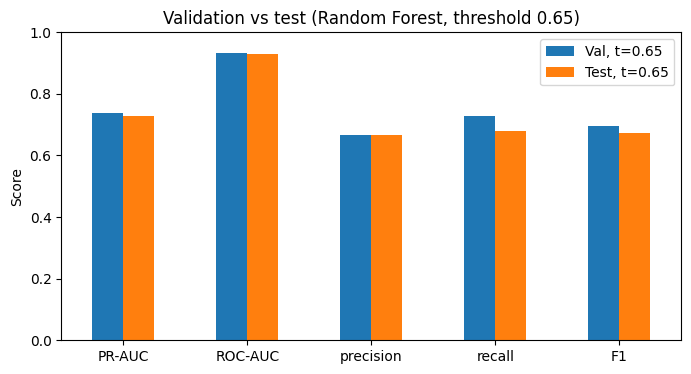

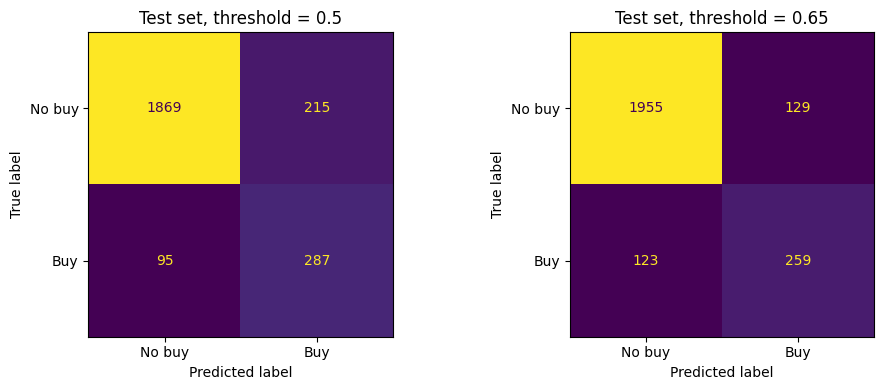

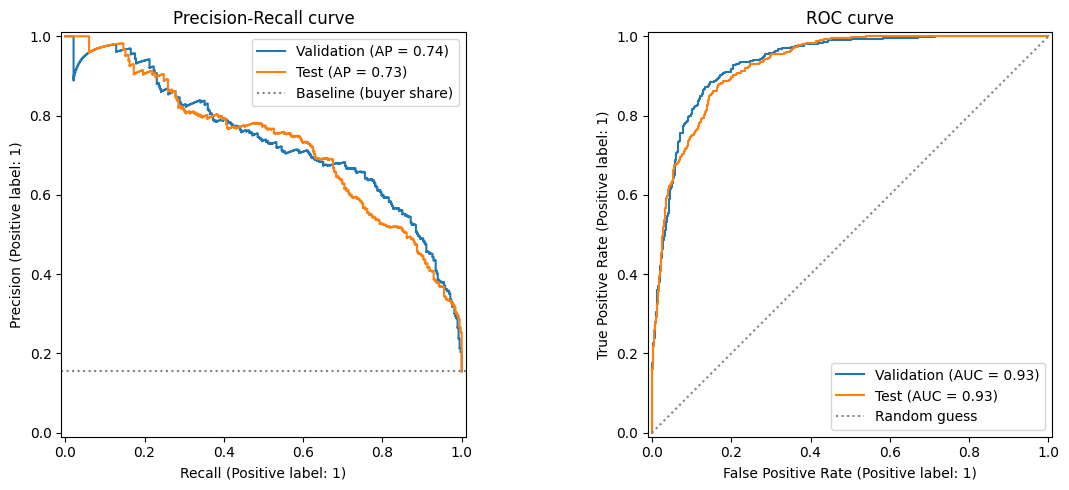

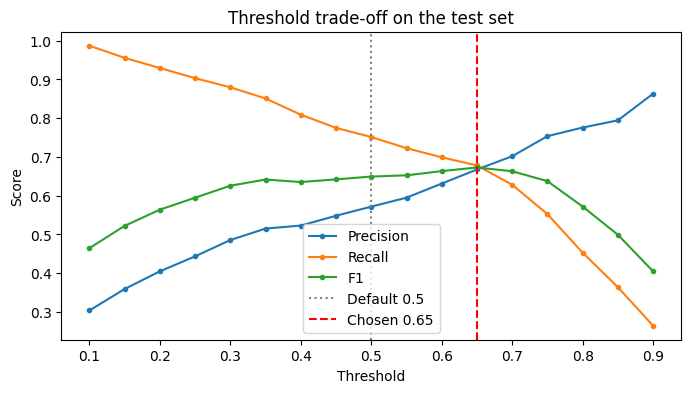

In [ ]:
# TODO: 8.1 graphs
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

# Graph 1: validation vs test at the final threshold
cols = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1"]
final_df.loc[["Val, t=0.65", "Test, t=0.65"], cols].T.plot(kind="bar", figsize=(8, 4))
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Validation vs test (Random Forest, threshold 0.65)")
plt.xticks(rotation=0)
plt.show()

# Graph 2: test confusion matrices, threshold 0.5 vs 0.65
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, t in zip(axes, [0.5, FINAL_THRESHOLD]):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= t).astype(int),
                                            display_labels=["No buy", "Buy"], ax=ax, colorbar=False)
    ax.set_title(f"Test set, threshold = {t}")
plt.tight_layout()
plt.show()

# Graph 3: PR curve and ROC curve, validation vs test
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
PrecisionRecallDisplay.from_predictions(y_val, proba_val, name="Validation", ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, proba_test, name="Test", ax=axes[0])
axes[0].axhline(y_test.mean(), color="gray", linestyle=":", label="Baseline (buyer share)")
axes[0].set_title("Precision-Recall curve")
axes[0].legend()
RocCurveDisplay.from_predictions(y_val, proba_val, name="Validation", ax=axes[1])
RocCurveDisplay.from_predictions(y_test, proba_test, name="Test", ax=axes[1])
axes[1].plot([0, 1], [0, 1], color="gray", linestyle=":", label="Random guess")
axes[1].set_title("ROC curve")
axes[1].legend()
plt.tight_layout()
plt.show()

# Graph 4: precision / recall / F1 vs threshold on the TEST set
test_thresholds = np.arange(0.10, 0.91, 0.05)
prec, rec, f1s = [], [], []
for t in test_thresholds:
    pred = (proba_test >= t).astype(int)
    prec.append(precision_score(y_test, pred))
    rec.append(recall_score(y_test, pred))
    f1s.append(f1_score(y_test, pred))

plt.figure(figsize=(8, 4))
plt.plot(test_thresholds, prec, marker=".", label="Precision")
plt.plot(test_thresholds, rec, marker=".", label="Recall")
plt.plot(test_thresholds, f1s, marker=".", label="F1")
plt.axvline(0.5, color="gray", linestyle=":", label="Default 0.5")
plt.axvline(FINAL_THRESHOLD, color="red", linestyle="--", label="Chosen 0.65")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold trade-off on the test set")
plt.legend()
plt.show()

**Result (8.1):** test set = 2,466 sessions, 382 buyers, baseline PR-AUC = 0.155

| | PR-AUC | ROC-AUC | Precision | Recall | F1 | Accuracy | TP | FP | FN | TN |
|---|---|---|---|---|---|---|---|---|---|---|
| Validation, t = 0.5 | 0.737 | 0.934 | 0.587 | 0.816 | 0.683 | 0.883 | 311 | 219 | 70 | 1866 |
| Validation, t = 0.65 | 0.737 | 0.934 | 0.667 | 0.730 | 0.697 | 0.902 | 278 | 139 | 103 | 1946 |
| Test, t = 0.5 | 0.728 | 0.929 | 0.572 | 0.751 | 0.649 | 0.874 | 287 | 215 | 95 | 1869 |
| **Test, t = 0.65 (final)** | **0.728** | **0.929** | **0.668** | **0.678** | **0.673** | **0.898** | **259** | **129** | **123** | **1955** |

**1. The model generalises well (validation → test):**
- **PR-AUC 0.737 → 0.728** (−0.009) and **ROC-AUC 0.934 → 0.929** (−0.005): very small drops, so our tuning did not overfit the validation set.
- PR-AUC 0.728 is **4.7× the baseline** (0.155).
- **Precision at 0.65 is unchanged** (0.667 → 0.668). **Recall is lower** on test (0.730 → 0.678), so F1 drops slightly (0.697 → 0.673).
  A small drop is expected, because the threshold was tuned on the validation set.

**2. The threshold effect holds on new data (RQ part 2):** moving from 0.5 to 0.65 on the test set:
| | t = 0.5 | t = 0.65 | Change |
|---|---|---|---|
| False alarms (FP) | 215 | 129 | **−86 (−40%)** |
| Buyers caught (TP) | 287 | 259 | −28 (−10%) |
| Precision | 0.572 | 0.668 | ↑ |
| Recall | 0.751 | 0.678 | ↓ |
| F1 | 0.649 | 0.673 | ↑ |

Raising the threshold removes **40% of the false alarms** while losing only **10% of the caught buyers**,
the same trade-off we saw on validation (−80 FP, −33 TP). This confirms that the threshold controls false positives.

**3. In plain words (final model, test set):**
- The model flags **388** sessions as buyers; **259 of them really buy**, so about **2 out of 3 flagged visitors are real buyers** (precision 0.668).
- It finds **259 of the 382 real buyers**, about **68%** (recall 0.678).
- Accuracy is 89.8%, compared with 84.5% for always predicting "no buy". As expected with imbalance, accuracy alone hides most of the difference.

**Note:** these results include PageValues, so they are the **optimistic** end (see 9.4). Section 8.2 tests the model without PageValues.



**Graphs (8.1):**

1. **Validation vs test (bar chart, threshold 0.65):**
   | Metric | Validation | Test | Change | % change |
   |---|---|---|---|---|
   | PR-AUC | 0.737 | 0.728 | −0.009 | −1.2% |
   | ROC-AUC | 0.934 | 0.929 | −0.005 | −0.5% |
   | Precision | 0.667 | 0.668 | +0.001 | +0.1% |
   | Recall | 0.730 | 0.678 | −0.052 | −7.1% |
   | F1 | 0.697 | 0.673 | −0.024 | −3.4% |

   The threshold-free metrics (PR-AUC, ROC-AUC) drop by **≈1% or less**, and precision is unchanged, so the model generalises well.
   Recall shows the largest drop (−7.1%), because the threshold was tuned on validation.

2. **Confusion matrices (test, threshold 0.5 → 0.65):**
   | | t = 0.5 | t = 0.65 | Change | % change |
   |---|---|---|---|---|
   | False alarms (FP) | 215 | 129 | −86 | **−40.0%** |
   | Buyers caught (TP) | 287 | 259 | −28 | **−9.8%** |
   | Missed buyers (FN) | 95 | 123 | +28 | +29.5% |
   | Sessions flagged (TP + FP) | 502 | 388 | −114 | −22.7% |
   | Precision | 0.572 | 0.668 | +0.096 | +16.8% |
   | Recall | 0.751 | 0.678 | −0.073 | −9.7% |

   Raising the threshold removes **40% of the false alarms** but loses only **about 10% of the caught buyers**:
   about **3 false alarms removed for every buyer lost** (86 / 28 ≈ 3.1).

3. **PR and ROC curves:** the validation and test curves **almost overlap** over the whole range of thresholds.
   Test PR-AUC (0.728) is **4.7× the baseline** (0.155), and test ROC-AUC (0.929) is far above random guessing (0.5).
   The test PR curve is only slightly lower at recall 0.6–0.9.

4. **Threshold trade-off (test):** as the threshold rises, precision goes **up** and recall goes **down**.
   - On the test set, **F1 is highest at 0.65**, the same threshold we chose on validation, and precision and recall **cross** there (≈ 0.67).
     So the validation-chosen threshold is also the best one on new data. (We did **not** use the test set to choose it.)
   - F1 is fairly **flat between 0.35 and 0.70** (≈ 0.64–0.67, within about 5%), so the result is not very sensitive to the exact threshold.
   - Above 0.7, recall drops sharply: from 0.678 at 0.65 to ≈ 0.26 at 0.9 (**≈ −62%**), so we would miss most buyers.
   - **Practical meaning:** a shop that cares more about avoiding false alarms (e.g. costly offers) can move the threshold up;
     one that wants to catch more buyers can move it down. The curve shows the cost of each choice.

### 8.2 Model without PageValues (sensitivity check)

**Why:** we suspect PageValues may partly contain the purchase outcome (leakage, see Section 9.4), but we cannot prove it,
because we do not know exactly how the page values were computed.
So we test how much the result **depends** on PageValues: if we could not trust it at all, how good would the model still be?

**How (same rules as the main model, no test-set decisions):**
1. Train a Random Forest on **16 features** (all except PageValues) on the **train set**,
   with the **same hyperparameters** as the main model (not re-tuned, to keep the comparison fair and simple).
2. Choose **its own threshold on the validation set** (best F1), exactly like Section 6.
   Its probabilities are different from the main model's, so 0.65 is not necessarily right for it.
3. Evaluate it **once** on the test set and compare with the final model from 8.1.

**Note:** this model is for **comparison only**. The final model remains the one from 8.1.

Best threshold without PageValues (validation): 0.55


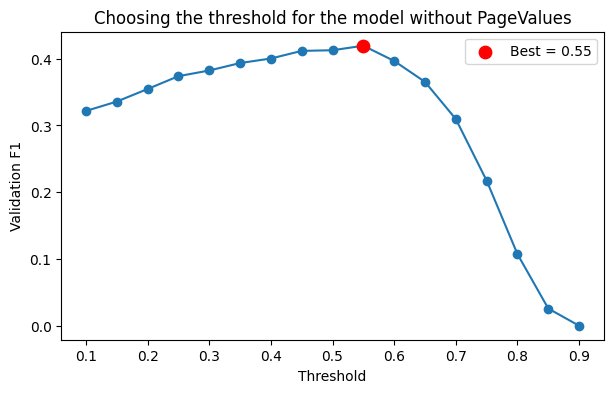

                       PR-AUC  ROC-AUC  precision  recall     F1  accuracy  \
Val, without PV         0.355    0.769      0.346   0.533  0.419     0.772   
Test, without PV        0.342    0.752      0.322   0.453  0.376     0.767   
Test, with PV (final)   0.728    0.929      0.668   0.678  0.673     0.898   

                          TP     FP     FN      TN  
Val, without PV        203.0  384.0  178.0  1701.0  
Test, without PV       173.0  365.0  209.0  1719.0  
Test, with PV (final)  259.0  129.0  123.0  1955.0  


In [ ]:
# TODO: 8.2 Model WITHOUT PageValues: train, choose threshold on validation, then test once
features_no_pv = [f for f in ALL_FEATURES if f != "PageValues"]

rf_no_pv = Pipeline([("prep", make_preprocessor(features_no_pv)),
                     ("model", clone(best_rf.named_steps["model"]))])
rf_no_pv.fit(X_train, y_train)

# Step 1: choose its threshold on the VALIDATION set (best F1)
thresholds = np.arange(0.10, 0.91, 0.05)
proba_val_no_pv = rf_no_pv.predict_proba(X_val)[:, 1]
f1_no_pv = [f1_score(y_val, (proba_val_no_pv >= t).astype(int), zero_division=0) for t in thresholds]
t_no_pv = round(thresholds[np.argmax(f1_no_pv)], 2)
print("Best threshold without PageValues (validation):", t_no_pv)

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1_no_pv, marker="o")
plt.scatter(t_no_pv, max(f1_no_pv), color="red", s=80, zorder=3, label=f"Best = {t_no_pv}")
plt.xlabel("Threshold")
plt.ylabel("Validation F1")
plt.title("Choosing the threshold for the model without PageValues")
plt.legend()
plt.show()

# Step 2: evaluate ONCE on the test set and compare with the final model
proba_test_no_pv = rf_no_pv.predict_proba(X_test)[:, 1]

compare_df = pd.DataFrame({
    "Val, without PV":       all_metrics(y_val, proba_val_no_pv, t_no_pv),
    "Test, without PV":      all_metrics(y_test, proba_test_no_pv, t_no_pv),
    "Test, with PV (final)": all_metrics(y_test, proba_test, FINAL_THRESHOLD),
}).T
print(compare_df.round(3))

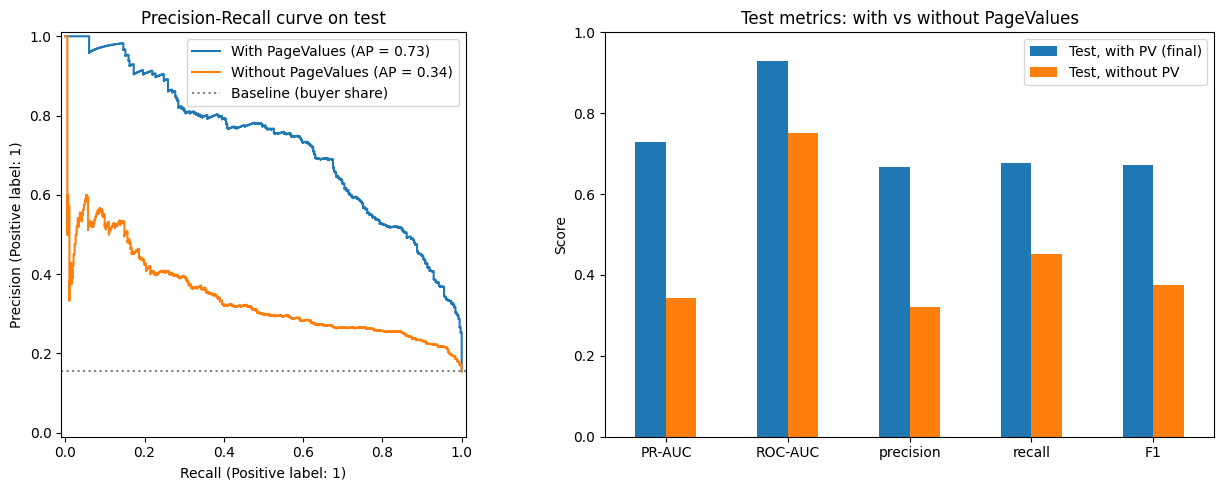

In [ ]:
# TODO: 8.2 graphs: with vs without PageValues on the TEST set
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graph 1: PR curves on test
PrecisionRecallDisplay.from_predictions(y_test, proba_test, name="With PageValues", ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, proba_test_no_pv, name="Without PageValues", ax=axes[0])
axes[0].axhline(y_test.mean(), color="gray", linestyle=":", label="Baseline (buyer share)")
axes[0].set_title("Precision-Recall curve on test")
axes[0].legend()

# Graph 2: bar chart of test metrics
cols = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1"]
compare_df.loc[["Test, with PV (final)", "Test, without PV"], cols].T.plot(kind="bar", ax=axes[1])
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Score")
axes[1].set_title("Test metrics: with vs without PageValues")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Result (8.2):** threshold chosen on validation = **0.55** (best F1 = 0.419)

**Threshold choice (F1 graph):** F1 is fairly flat between 0.45 and 0.55 (≈ 0.41–0.42), then falls sharply after 0.6
and reaches 0 at 0.9. Without PageValues the model is **rarely confident**, so a high threshold flags almost nobody.
Its best threshold (0.55) is lower than the main model's (0.65).

**1. Validation vs test (without PageValues):**
| Metric | Validation | Test | % change |
|---|---|---|---|
| PR-AUC | 0.355 | 0.342 | −3.7% |
| ROC-AUC | 0.769 | 0.752 | −2.2% |
| Precision | 0.346 | 0.322 | −6.9% |
| Recall | 0.533 | 0.453 | −15.0% |
| F1 | 0.419 | 0.376 | −10.3% |

The validation result from 7.3 (0.355) is confirmed on the test set (0.342).

**2. With vs without PageValues (test set):**
| Metric | With PV (t = 0.65) | Without PV (t = 0.55) | Change | % change |
|---|---|---|---|---|
| PR-AUC | 0.728 | 0.342 | −0.386 | **−53.0%** |
| ROC-AUC | 0.929 | 0.752 | −0.177 | −19.1% |
| Precision | 0.668 | 0.322 | −0.346 | **−51.8%** |
| Recall | 0.678 | 0.453 | −0.225 | −33.2% |
| F1 | 0.673 | 0.376 | −0.297 | **−44.1%** |
| Accuracy | 0.898 | 0.767 | −0.131 | −14.6% |
| Buyers caught (TP) | 259 | 173 | −86 | −33.2% |
| False alarms (FP) | 129 | 365 | +236 | **+183%** |
| Missed buyers (FN) | 123 | 209 | +86 | +69.9% |

**Observations:**
- **Removing PageValues roughly halves performance:** PR-AUC drops by 53% and precision by 52%.
- **False alarms almost triple** (129 → 365), while **one third fewer buyers** are caught (259 → 173).
- **In plain words:** with PageValues, about **2 out of 3** flagged visitors really buy; without it, only about **1 out of 3**.
  It finds 45% of buyers instead of 68%.
- Its **accuracy (76.7%) is even below** always predicting "no buy" (84.5%), because it raises so many false alarms at its best-F1 threshold.
  This again shows why accuracy is not a good metric here.
- **Still better than guessing:** PR-AUC 0.342 is **2.2× the baseline** (0.155), so the other 16 features carry some real signal.
  But measured above the baseline (0.342 − 0.155 = 0.187 vs 0.728 − 0.155 = 0.573), the model keeps only about **one third** of its useful predictive power.

**PR curve:** the model without PageValues (orange) stays far below the main model (blue) at **every** recall level.
Its precision is mostly 0.25–0.45 and approaches the baseline at high recall, while the main model stays above 0.5 up to about 90% recall.

**Conclusion:** on unseen data, our model's performance depends heavily on PageValues.
The real-world performance probably lies **between 0.342 (worst case, no PageValues) and 0.728 (optimistic, PageValues as given)**,
depending on how PageValues would be computed and when it is available (see Section 9.4).
This check shows **dependence**, not proof of leakage: a big drop would also happen if PageValues were simply a genuinely strong feature.

### 8.3 Bootstrap confidence intervals

**Why we do it:**
Our test results are single numbers (e.g. PR-AUC = 0.728). But they depend on *which* 2,466 sessions happened to end up in the test set.
With a different random test set, the scores would be slightly different. A single number hides this uncertainty.
Bootstrap estimates **how much the scores could vary just from the luck of the sample**, and gives a **95% confidence interval (CI)** for each metric.

This lets us answer three questions:
1. **How reliable is our final score?** A narrow interval means a stable result.
2. **Is the gap between "with" and "without PageValues" real?** If the CI of the gap does not include 0, the difference is not due to chance.
3. **Is the threshold effect real (RQ part 2)?** Does moving from 0.5 to 0.65 *always* remove false alarms, and how many buyers does it cost?

**What bootstrap is:**
We create many "new" test sets from the one we have, by **resampling with replacement**:
from the 2,466 test sessions, draw 2,466 at random, where the same session can be picked more than once and some are not picked at all.
This mimics drawing a new sample of visitors from the same population.

**How we do it:**
1. Take the **already computed test predictions** of both models (from 8.1 and 8.2). **No retraining**, and thresholds stay fixed (0.65 and 0.55).
2. Draw a bootstrap sample of 2,466 test sessions with replacement.
3. Calculate the metrics on this sample: PR-AUC, F1, precision, recall, the PR-AUC gap (with − without PageValues),
   and the number of false alarms removed and buyers lost when moving from threshold 0.5 to 0.65.
4. Repeat **1,000 times**, which gives 1,000 values for each metric.
5. The **95% CI** is the range between the 2.5th and 97.5th percentiles of these 1,000 values (the middle 95%).

**How to read it:**
- "PR-AUC = 0.728 (95% CI a–b)": with a different test sample, PR-AUC would very likely lie between a and b.
- If the CI of a **difference** (gap, false alarms removed) does **not contain 0**, the difference is statistically reliable.

**Limitation:** bootstrap only measures uncertainty from the **test sample**. It does not include the variation from training
(a different train split or random seed could give a slightly different model).

In [ ]:
# TODO: 8.3 Bootstrap 95% confidence intervals on the test set (no retraining)
def boot_metrics(y, p_pv, p_no_pv):
    pred_65 = (p_pv >= FINAL_THRESHOLD).astype(int)      # final model, threshold 0.65
    pred_50 = (p_pv >= 0.5).astype(int)                  # final model, default threshold
    pred_no_pv = (p_no_pv >= t_no_pv).astype(int)        # model without PageValues, threshold 0.55
    return {
        "PR-AUC (with PV)":    average_precision_score(y, p_pv),
        "F1 (with PV)":        f1_score(y, pred_65),
        "Precision (with PV)": precision_score(y, pred_65),
        "Recall (with PV)":    recall_score(y, pred_65),
        "PR-AUC (without PV)": average_precision_score(y, p_no_pv),
        "F1 (without PV)":     f1_score(y, pred_no_pv),
        "PR-AUC gap (with - without)": average_precision_score(y, p_pv) - average_precision_score(y, p_no_pv),
        "False alarms removed (0.5 -> 0.65)": ((pred_50 == 1) & (y == 0)).sum() - ((pred_65 == 1) & (y == 0)).sum(),
        "Buyers lost (0.5 -> 0.65)":          ((pred_50 == 1) & (y == 1)).sum() - ((pred_65 == 1) & (y == 1)).sum(),
    }

y_test_arr = y_test.to_numpy()
n = len(y_test_arr)
N_BOOT = 1000
rng = np.random.default_rng(RANDOM_STATE)

boot_rows = []
for i in range(N_BOOT):
    idx = rng.integers(0, n, n)          # n random positions, with replacement
    boot_rows.append(boot_metrics(y_test_arr[idx], proba_test[idx], proba_test_no_pv[idx]))
boot_df = pd.DataFrame(boot_rows)

ci_df = pd.DataFrame({
    "estimate (full test)": pd.Series(boot_metrics(y_test_arr, proba_test, proba_test_no_pv)),
    "95% CI lower": boot_df.quantile(0.025),
    "95% CI upper": boot_df.quantile(0.975),
})
pd.set_option("display.width", 200)
print(ci_df.round(3))

                                    estimate (full test)  95% CI lower  95% CI upper
PR-AUC (with PV)                                   0.728         0.682         0.770
F1 (with PV)                                       0.673         0.632         0.711
Precision (with PV)                                0.668         0.616         0.716
Recall (with PV)                                   0.678         0.632         0.725
PR-AUC (without PV)                                0.342         0.299         0.393
F1 (without PV)                                    0.376         0.334         0.414
PR-AUC gap (with - without)                        0.386         0.337         0.430
False alarms removed (0.5 -> 0.65)                86.000        69.000       105.000
Buyers lost (0.5 -> 0.65)                         28.000        19.000        38.000


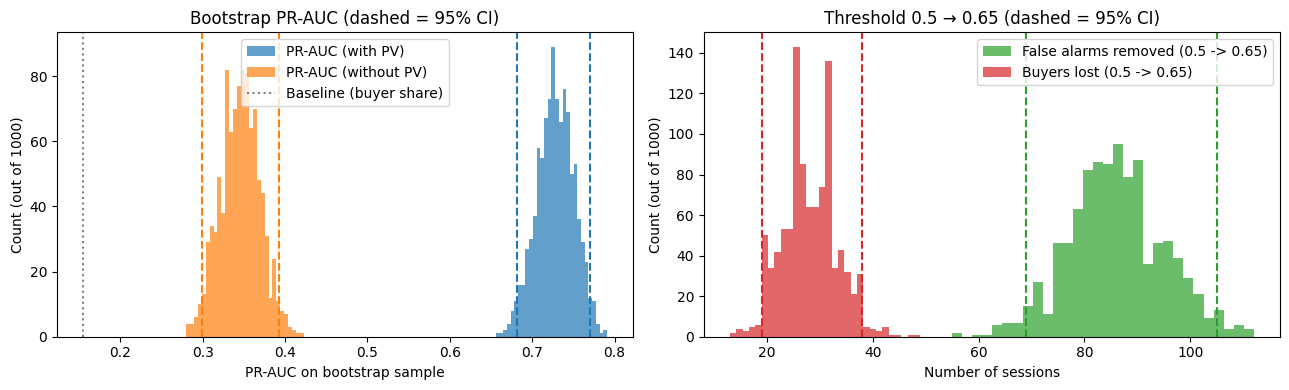

In [ ]:
# TODO: 8.3 graphs: bootstrap distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Graph 1: PR-AUC with vs without PageValues
for col, color in [("PR-AUC (with PV)", "tab:blue"), ("PR-AUC (without PV)", "tab:orange")]:
    axes[0].hist(boot_df[col], bins=30, alpha=0.7, color=color, label=col)
    axes[0].axvline(ci_df.loc[col, "95% CI lower"], color=color, linestyle="--")
    axes[0].axvline(ci_df.loc[col, "95% CI upper"], color=color, linestyle="--")
axes[0].axvline(y_test.mean(), color="gray", linestyle=":", label="Baseline (buyer share)")
axes[0].set_xlabel("PR-AUC on bootstrap sample")
axes[0].set_ylabel("Count (out of 1000)")
axes[0].set_title("Bootstrap PR-AUC (dashed = 95% CI)")
axes[0].legend()

# Graph 2: threshold effect 0.5 -> 0.65
for col, color in [("False alarms removed (0.5 -> 0.65)", "tab:green"), ("Buyers lost (0.5 -> 0.65)", "tab:red")]:
    axes[1].hist(boot_df[col], bins=30, alpha=0.7, color=color, label=col)
    axes[1].axvline(ci_df.loc[col, "95% CI lower"], color=color, linestyle="--")
    axes[1].axvline(ci_df.loc[col, "95% CI upper"], color=color, linestyle="--")
axes[1].set_xlabel("Number of sessions")
axes[1].set_ylabel("Count (out of 1000)")
axes[1].set_title("Threshold 0.5 → 0.65 (dashed = 95% CI)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Result (8.3):** 1,000 bootstrap samples of the test set (no retraining, fixed thresholds)

| Metric | Estimate (full test) | 95% CI |
|---|---|---|
| **PR-AUC (with PageValues)** | **0.728** | **0.682 – 0.770** |
| F1 (with PV, t = 0.65) | 0.673 | 0.632 – 0.711 |
| Precision (with PV, t = 0.65) | 0.668 | 0.616 – 0.716 |
| Recall (with PV, t = 0.65) | 0.678 | 0.632 – 0.725 |
| PR-AUC (without PageValues) | 0.342 | 0.299 – 0.393 |
| F1 (without PV, t = 0.55) | 0.376 | 0.334 – 0.414 |
| **PR-AUC gap (with − without)** | **0.386** | **0.337 – 0.430** |
| **False alarms removed (0.5 → 0.65)** | **86** | **69 – 105** |
| **Buyers lost (0.5 → 0.65)** | **28** | **19 – 38** |

**1. How reliable is the final score?**
- PR-AUC 0.728 has a 95% CI of **0.682–0.770** (about ±0.04, or ±6%). With a different test sample, PR-AUC would very likely stay in this range.
- The **validation PR-AUC (0.737) lies inside this interval**, so the small validation → test drop (−0.009) is consistent with random sampling variation, not overfitting.
- Even the lower end (0.682) is **4.4× the baseline** (0.155).

**2. Is the PageValues gap real?**
- The CI of the gap is **0.337–0.430** and **does not contain 0**, so the drop without PageValues is **not due to chance**.
- In the histogram, the two distributions (blue vs orange) **do not overlap at all**.
- Even without PageValues, the lower end (0.299) is still well above the baseline (0.155), so the other features carry real signal.

**3. Is the threshold effect real (RQ part 2)?**
- Moving from 0.5 to 0.65 removes **69–105 false alarms** and loses **19–38 buyers** (95% CIs). **Neither interval contains 0**, so both effects are real.
- The intervals **do not overlap**: even in the least favourable case (69 removed) more false alarms are removed than buyers are lost in the worst case (38).
  The trade-off is consistently about **3 false alarms removed per buyer lost**.

**Graphs:**
- **Left:** the 1,000 PR-AUC values with PageValues (blue, around 0.73) and without (orange, around 0.34) form two clearly separate peaks, both far to the right of the baseline (grey line).
- **Right:** the "false alarms removed" values (green, around 86) all lie well above the "buyers lost" values (red, around 28), so raising the threshold always pays off in this sense.

**Limitation:** these intervals only cover variation from the **test sample**. They do not include variation from training (a different split or random seed).
Training variation was partly addressed with 5-fold cross-validation in Section 5.

### 8.4 Error analysis: which sessions does the model get wrong?

**Why:** a single score does not show *where* the model fails. We look at the four outcome groups on the test set
(final model, threshold 0.65) and compare what their sessions look like:

| Group | Meaning |
|---|---|
| **TP** (buyer caught) | Bought, and the model flagged them |
| **FN** (missed buyer) | Bought, but the model did not flag them |
| **FP** (false alarm) | Did not buy, but the model flagged them |
| **TN** (correct no-buy) | Did not buy, and the model did not flag them |

**How:** for each group we compare the average predicted probability and the key features from Section 7
(PageValues, ExitRates, ProductRelated, Month, VisitorType). We also show the **most confident mistakes**:
the false alarms with the highest probability and the missed buyers with the lowest probability.

This is done **after** the final evaluation, only to understand the errors. Nothing in the model or threshold is changed.

,sessions,mean_proba,share_PageValues_gt0,median_PageValues,mean_ExitRates,median_ProductRelated,share_November,share_New_Visitor
group,,,,,,,,
TP (buyer caught),259,0.854,0.996,25.188,0.017,28.0,0.390,0.259
FN (missed buyer),123,0.352,0.325,0.000,0.031,29.0,0.593,0.179
FP (false alarm),129,0.779,1.000,18.041,0.021,35.0,0.310,0.062
TN (correct no-buy),1955,0.114,0.056,0.000,0.047,15.0,0.217,0.128


Missed buyers: 123, of which 83 have PageValues = 0 and 28 have probability between 0.5 and 0.65

Most confident false alarms (highest probability, did not buy):


,proba,PageValues,ExitRates,BounceRates,ProductRelated,Month,VisitorType
6429,0.979,166.374,0.006,0.0,15,June,New_Visitor
6054,0.955,63.553,0.033,0.0,6,Jul,Returning_Visitor
675,0.954,18.585,0.010,0.0,20,Mar,Returning_Visitor
7956,0.950,29.462,0.029,0.0,9,Aug,Returning_Visitor
8553,0.947,12.586,0.023,0.0,12,Nov,Returning_Visitor


Most confident missed buyers (lowest probability, did buy):


,proba,PageValues,ExitRates,BounceRates,ProductRelated,Month,VisitorType
12086,0.040,0.0,0.067,0.033,6,Nov,Returning_Visitor
11798,0.054,0.0,0.067,0.000,6,Nov,Returning_Visitor
6561,0.080,0.0,0.007,0.008,24,Aug,Returning_Visitor
10789,0.091,0.0,0.200,0.200,1,Nov,Returning_Visitor
6767,0.096,0.0,0.020,0.010,18,Oct,Returning_Visitor


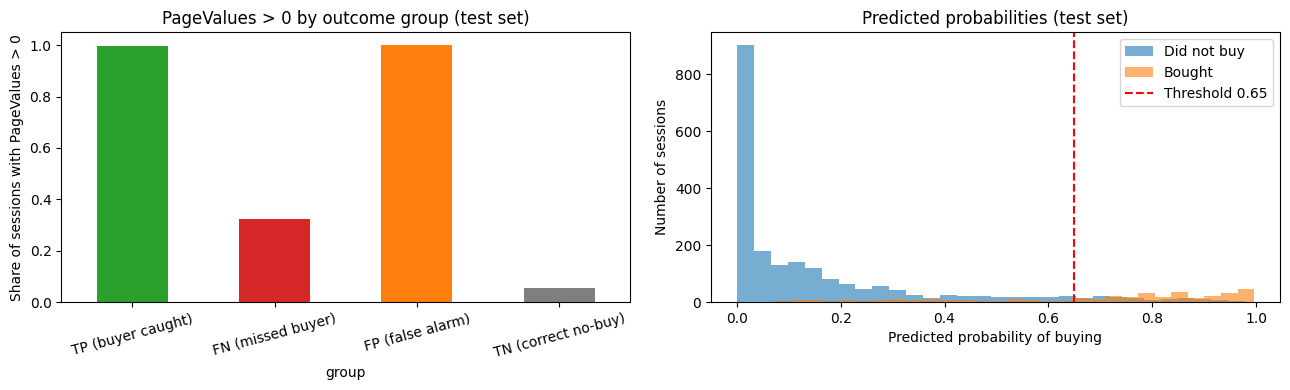

In [ ]:
# TODO: 8.4 Error analysis on the TEST set (final model, threshold 0.65)
err_df = X_test.copy()
err_df["actual"] = y_test.values
err_df["proba"] = proba_test
err_df["pred"] = (proba_test >= FINAL_THRESHOLD).astype(int)

# TODO: label each session as TP / FN / FP / TN
err_df["group"] = np.select(
    [(err_df["actual"] == 1) & (err_df["pred"] == 1),
     (err_df["actual"] == 1) & (err_df["pred"] == 0),
     (err_df["actual"] == 0) & (err_df["pred"] == 1),
     (err_df["actual"] == 0) & (err_df["pred"] == 0)],
    ["TP (buyer caught)", "FN (missed buyer)", "FP (false alarm)", "TN (correct no-buy)"],
    default="other")
order = ["TP (buyer caught)", "FN (missed buyer)", "FP (false alarm)", "TN (correct no-buy)"]

# TODO: compare the four groups
summary_err = err_df.groupby("group").agg(
    sessions=("actual", "size"),
    mean_proba=("proba", "mean"),
    share_PageValues_gt0=("PageValues", lambda s: (s > 0).mean()),
    median_PageValues=("PageValues", "median"),
    mean_ExitRates=("ExitRates", "mean"),
    median_ProductRelated=("ProductRelated", "median"),
    share_November=("Month", lambda s: (s == "Nov").mean()),
    share_New_Visitor=("VisitorType", lambda s: (s == "New_Visitor").mean()),
).loc[order]
display(summary_err.round(3))

# TODO: missed buyers that the default threshold 0.5 would have caught
fn = err_df[err_df["group"] == "FN (missed buyer)"]
print(f"Missed buyers: {len(fn)}, of which {(fn['PageValues'] == 0).sum()} have PageValues = 0 "
      f"and {(fn['proba'] >= 0.5).sum()} have probability between 0.5 and 0.65")

# TODO: the most confident mistakes
cols_show = ["proba", "PageValues", "ExitRates", "BounceRates", "ProductRelated", "Month", "VisitorType"]
print("\nMost confident false alarms (highest probability, did not buy):")
display(err_df[err_df["group"] == "FP (false alarm)"].sort_values("proba", ascending=False)[cols_show].head(5).round(3))
print("Most confident missed buyers (lowest probability, did buy):")
display(fn.sort_values("proba")[cols_show].head(5).round(3))

# TODO: graphs
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
summary_err["share_PageValues_gt0"].plot(kind="bar", ax=axes[0], color=["tab:green", "tab:red", "tab:orange", "tab:gray"])
axes[0].set_ylabel("Share of sessions with PageValues > 0")
axes[0].set_title("PageValues > 0 by outcome group (test set)")
axes[0].tick_params(axis="x", rotation=15)

axes[1].hist(err_df.loc[err_df["actual"] == 0, "proba"], bins=30, alpha=0.6, label="Did not buy")
axes[1].hist(err_df.loc[err_df["actual"] == 1, "proba"], bins=30, alpha=0.6, label="Bought")
axes[1].axvline(FINAL_THRESHOLD, color="red", linestyle="--", label="Threshold 0.65")
axes[1].set_xlabel("Predicted probability of buying")
axes[1].set_ylabel("Number of sessions")
axes[1].set_title("Predicted probabilities (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Result (8.4):** test set, final model, threshold 0.65

| Group | Sessions | Mean probability | PageValues > 0 | Median PageValues | Mean ExitRates | Median product pages | November | New visitors |
|---|---|---|---|---|---|---|---|---|
| TP (buyer caught) | 259 | 0.854 | 99.6% | 25.2 | 0.017 | 28 | 39.0% | 25.9% |
| **FN (missed buyer)** | **123** | 0.352 | **32.5%** | **0** | 0.031 | 29 | **59.3%** | 17.9% |
| **FP (false alarm)** | **129** | 0.779 | **100%** | 18.0 | 0.021 | 35 | 31.0% | 6.2% |
| TN (correct no-buy) | 1955 | 0.114 | 5.6% | 0 | 0.047 | 15 | 21.7% | 12.8% |

**Observations:**
- **Most errors are explained by PageValues.**
  - **Missed buyers:** 83 of the 123 (**67%**) have **PageValues = 0**. Without a page value, the model rarely believes a session will buy,
    even though these buyers browsed as many product pages as caught buyers (median 29 vs 28).
  - **False alarms:** **all 129** have PageValues > 0 (median 18.0). They look like buyers (valuable pages, low exit rates, many product pages, median 35),
    so the model flags them, but they did not buy. The most confident false alarms (probability ≥ 0.95) have high page values (12.6–166.4) and zero bounce rate,
    so they are almost indistinguishable from real buyers with the available features.
- **Missed buyers are often in November** (59% vs 39% of caught buyers). In the busiest shopping month, some buyers complete a purchase
  without passing through pages with a page value, which the model cannot detect.
- **False alarms are mostly returning visitors** (only 6% new visitors vs 26% among caught buyers): returning visitors who browse valuable pages but do not buy
  (for example, comparing products or coming back later).
- **28 missed buyers** have probabilities between 0.5 and 0.65, so they would be caught at the default threshold 0.5,
  at the cost of more false alarms (Section 8.1: 215 vs 129).
- **Some errors cannot be fixed with these features:** e.g. missed buyer #10789 viewed 1 product page with bounce and exit rates of 0.2,
  which looks exactly like a bounce session.

**Probability histogram:** most non-buyers get probabilities near 0 and most buyers are above 0.65.
Errors come from the **overlap** between about 0.3 and 0.8, where buyers and non-buyers look alike.

**Conclusion:** the model's errors mirror its strength: it relies on PageValues, so it **misses buyers without a page value**
and **raises false alarms for non-buyers with one**. This confirms the dependence discussed in 8.2 and 9.4,
and suggests that features capturing purchase intent beyond PageValues would be needed to reduce both error types.

## 9. Conclusions and limitations

**Research question:** How do feature importance and classification thresholds affect performance
in identifying purchasing sessions while controlling false positives?

### 9.1 Summary of results

**Model selection (validation set, Section 5):**
| Model | Validation PR-AUC | Validation ROC-AUC | Best F1 (threshold) |
|---|---|---|---|
| Baseline (always "no buy") | 0.155 | 0.500 | 0 |
| Logistic Regression (C = 0.01, balanced) | 0.687 | 0.923 | 0.693 (0.65) |
| **Random Forest** (300 trees, depth 10, leaf 5, max_features 0.5, balanced) | **0.737** | **0.934** | **0.697 (0.65)** |

Random Forest was chosen: PR-AUC +0.05 over Logistic Regression (above our 0.02 rule).

**Final model on the test set (used once, Section 8):**
| Model | Threshold | PR-AUC (95% CI) | Precision | Recall | F1 |
|---|---|---|---|---|---|
| **Random Forest, all 17 features** | **0.65** | **0.728 (0.682–0.770)** | **0.668** | **0.678** | **0.673** |
| Random Forest, without PageValues | 0.55 | 0.342 (0.299–0.393) | 0.322 | 0.453 | 0.376 |
| Baseline (buyer share) | – | 0.155 | – | – | – |

**Key numbers:**
- The final model reaches **PR-AUC 0.728 on unseen data, 4.7× the baseline**, only 0.009 below validation (inside the 95% CI), so it **generalises well**.
- At threshold 0.65, **2 out of 3 flagged visitors really buy** (precision 0.668), and the model finds **2 out of 3 real buyers** (recall 0.678).
- Accuracy is 89.8% vs 84.5% for always predicting "no buy". As expected with imbalance, accuracy hides most of the difference, which is why PR-AUC was our main metric.

### 9.2 Which features matter?

**Answer:** purchase prediction is driven mainly by **PageValues**, followed by **exit/bounce behaviour** and the **month** of the visit.
Page counts add a little, while technical and visitor codes add nothing. About **5 of the 17 features** are enough.

**Evidence (Section 7):** five different checks give the same ranking.
| Rank | Feature(s) | Evidence |
|---|---|---|
| 1 | **PageValues** | Permutation drop 0.531 (≈12× the next feature); largest LR coefficient (+1.33); alone reaches PR-AUC 0.620 (84% of the full model); without it the test PR-AUC falls from 0.728 to 0.342 |
| 2 | **ExitRates, BounceRates** | Permutation drops 0.044 / 0.034; negative LR coefficients (visitors on pages people usually leave from rarely buy); removing them costs −0.033 PR-AUC |
| 3 | **Month** | Permutation drop 0.041; November strongly positive (+0.67), May / March / December negative; removing time context costs −0.022 |
| 4 | **ProductRelated, Administrative** (page counts) | Small gains (≈0.02); largely overlap with PageValues, so removing all page-behaviour features costs only −0.004 |
| – | OperatingSystems, Browser, Region, TrafficType, VisitorType, Informational pages, Weekend, SpecialDay | Permutation importance ≈ 0; removing visitor/tech features changes PR-AUC by +0.002 (noise) |

- **Agreement across methods and models:** Random Forest (permutation), Logistic Regression (coefficients) and retraining (ablation, top-k curve) agree,
  so the ranking does not depend on one model or one method.
- **How many features are needed:** the top-k curve levels off after **5 features** (PageValues, ExitRates, Month, BounceRates, ProductRelated),
  reaching PR-AUC 0.742 vs 0.737 for all 17 features on validation.
- **PCA did not help:** compressing the features into components lowered PR-AUC (RF −0.017 at best) and removed interpretability.

**Practical meaning:** a shop does not need to collect all 17 features. Tracking page values, exit/bounce rates, the month and product-page counts
would give almost the same performance. The technical codes (browser, OS, region, traffic source) can be dropped.
Because the model relies so heavily on PageValues, its quality depends on how reliably this feature is computed (see Section 9.4).

### 9.3 How does the threshold control false positives?

**Answer:** the classification threshold directly trades **false alarms** against **missed buyers**.
Raising it from the default **0.5 to 0.65** removes about **40% of the false alarms** while losing only about **10% of the caught buyers**,
about **3 false alarms removed for every buyer lost**. This effect was found on validation, confirmed on the unseen test set,
and shown to be statistically reliable with bootstrap.

**Evidence:**
| | Validation (0.5 → 0.65) | Test (0.5 → 0.65) | Test 95% CI (bootstrap) |
|---|---|---|---|
| False alarms (FP) | 219 → 139 (−80) | 215 → 129 (**−86, −40%**) | 69 – 105 removed |
| Buyers caught (TP) | 311 → 278 (−33) | 287 → 259 (**−28, −10%**) | 19 – 38 lost |
| Precision | 0.587 → 0.667 | 0.572 → 0.668 | 0.616 – 0.716 (at 0.65) |
| Recall | 0.816 → 0.730 | 0.751 → 0.678 | 0.632 – 0.725 (at 0.65) |
| F1 | 0.683 → 0.697 | 0.649 → 0.673 | 0.632 – 0.711 (at 0.65) |

- Neither bootstrap interval contains 0, and they do not overlap: raising the threshold **always** removes more false alarms than buyers lost.
- **0.65 was chosen on validation (best F1) and was independently also the best-F1 threshold on the test set**, where precision and recall are balanced (≈ 0.67).
- F1 is fairly flat between about 0.35 and 0.70, so nearby thresholds perform similarly; the gain comes from moving **away from 0.5**, not from 0.65 being uniquely perfect.
- The best threshold **depends on the model**: the model without PageValues is less confident, and its best threshold was 0.55.
  A threshold must therefore be tuned for each model, never copied from another.

**Is 0.65 "the best" threshold?** Only in the sense of **F1**, which treats a false alarm and a missed buyer as **equally bad**.
In practice, the right threshold depends on the cost of each mistake:

| Goal | Threshold (test set) | Precision / Recall | When to use | Example action |
|---|---|---|---|---|
| Maximise **precision** | Higher (≈ 0.75–0.9) | ≈ 0.75–0.86 / ≈ 0.55–0.26 | False alarms are **costly** | Personal sales call, large voucher |
| Maximise **F1** (our choice) | **0.65** | **0.668 / 0.678** | Both errors matter equally, or costs unknown | General "likely buyer" list |
| Maximise **recall** | Lower (≈ 0.3) | ≈ 0.49 / ≈ 0.88 | Missing a buyer is costly, false alarms cheap | Free chat pop-up, reminder email |

(≈ values read from the test-set threshold graph in 8.1)

**Why we used F1:** the dataset contains **no cost information**, and the research question values both **finding buyers** and **controlling false positives**.
If costs were known, the threshold could be chosen with **F-beta** (F0.5 favours precision, F2 favours recall)
or with a rule such as *"highest recall while keeping precision ≥ 0.75"*.

**Conclusion:** the threshold is a **business decision**, not only a technical one. The model gives a probability;
the threshold turns it into an action. Our trade-off curve (8.1) shows the cost of each choice, so a shop can pick the threshold that matches its budget for false alarms.

In [ ]:
# TODO: PageValues = 0 vs > 0, by buyer / non-buyer (full dataset)
pv_table = pd.crosstab(df["PageValues"] > 0, df["Revenue"], margins=True, margins_name="Total")
pv_table.index = ["PageValues = 0", "PageValues > 0", "Total"]
pv_table.columns = ["No purchase", "Purchase", "Total"]
pv_table["Buy rate"] = (pv_table["Purchase"] / pv_table["Total"]).round(3)
pv_table

,No purchase,Purchase,Total,Buy rate
PageValues = 0,9230,370,9600,0.039
PageValues > 0,1192,1538,2730,0.563
Total,10422,1908,12330,0.155


### 9.4 PageValues: leakage or strong feature, and real-time use

**What PageValues is:** BounceRates, ExitRates and PageValues are Google Analytics metrics measured for each page of the shop (UCI dataset description).
Google Analytics calculates a page's value as:

Page Value = (e-commerce revenue + goal value) ÷ unique pageviews of that page

Only pages viewed *before* a transaction get credit, and the value is pooled over all sessions in the reporting period.
A session's PageValues is the average value of the pages it visited.

**Leakage or strong feature?** The key question is: *could we know the value at prediction time without already knowing the answer?*
- **Strong feature:** each page's value is computed from **past** purchases by *other* visitors ("people who viewed these pages usually bought").
  It is known before the current visitor buys, so it is fair to use.
- **Leakage:** the page values include the **current** session's own purchase, so part of the answer is inside the feature.

**Our conclusion: PageValues is a strong, legitimate feature.**
In a real system, page values would be computed from past data, refreshed at regular intervals, and averaged over the pages a visitor has seen so far,
updated after each new page. The model would also be **retrained regularly** on recent sessions,
with page values computed from data *before* each session, so that training and real-time use compute the feature the same way.

**Remaining caveat:** the dataset does not document which period the page values were computed from.
If it was the same year as the sessions, a buyer's own purchase could contribute a small part of their pages' values (**possible small leakage**),
diluted by the many other sessions in each page's average. Our data suggests this effect is limited:
**370 buyers (19%) have PageValues = 0** and **1,192 non-buyers have PageValues > 0**, which does not fit a feature built from each session's own purchase.

**Finished sessions vs real time:**
Each row is one **completed** session with totals over the whole visit, so our model classifies completed sessions.
In real time, the features would be updated after every page and the prediction repeated; a visitor would be flagged once the probability crosses the threshold.
Two risks of this, which we cannot test with this dataset:
1. **Late alarm:** The model learned from *finished* sessions (e.g. buyers usually end with many pages and long durations).
   Early in a visit, a future buyer has only a few pages and little time, so they do not yet look like a buyer.
   The probability may only cross the threshold near the end of the visit, leaving little time to act.
2. **More false alarms:** checking after every page gives more chances to cross the threshold by mistake.

**Consequence for our results:**
| Model | Test PR-AUC (95% CI) | Interpretation |
|---|---|---|
| With PageValues | 0.728 (0.682–0.770) | Main result; possibly slightly optimistic |
| Without PageValues | 0.342 (0.299–0.393) | Worst case if PageValues were unavailable |

Regardless of leakage, the model **depends heavily** on PageValues (PR-AUC roughly halves without it),
so its real-world quality depends on computing this feature reliably.

### 9.5 Limitations

**Data limitations:**
| Limitation | Effect on our results |
|---|---|
| **One online shop, one year** of sessions | Results may not transfer to other shops, products or years (e.g. different seasons or customer behaviour) |
| **January and April are missing** | The Month effect is based on 10 months only; we cannot say anything about those two months |
| **Anonymised codes** (OperatingSystems, Browser, Region, TrafficType) | We cannot interpret them (e.g. which traffic source "8" is); they showed no reliable effect anyway |
| **Completed sessions only** (one row per finished visit) | Our model classifies finished sessions; real-time prediction during a visit could not be tested (see 9.4) |
| **PageValues computation period not documented** | Possible small leakage; test PR-AUC 0.728 may be slightly optimistic (see 9.4) |
| **125 duplicate rows kept** | They looked like genuine separate bounce sessions (all non-buyers); removing them would have changed results very little |

**Method limitations:**
| Limitation | Effect on our results |
|---|---|
| **Threshold chosen by F1**, which treats a false alarm and a missed buyer as equally bad | The best threshold in practice depends on real costs, which the dataset does not contain (see 9.3) |
| **Only two model types** (Logistic Regression and Random Forest) | Other models (e.g. gradient boosting) might perform better; not tested |
| **Limited hyperparameter grids** | A wider search might give a small improvement, though RF scores were already flat across the grid (0.718–0.748) |
| **Model without PageValues was not re-tuned** (same settings as the main model) | Its score (0.342) may be slightly lower than a fully tuned version |
| **Feature analysis on the validation set** (permutation, ablation, top-k) | The top-k curve is slightly optimistic, since the ranking and the scoring both used validation; used for analysis only |
| **One random train/validation/test split** (seed 42) | Results could change slightly with another split; bootstrap (8.3) only covers variation in the test sample, not in training |
| **Imbalance handled only with class weights** | Other methods (e.g. oversampling) were not compared |

**Interpretation limitation:**
- The model finds **associations, not causes**. For example, November sessions buy more often,
  but the month itself may not *cause* buying (it may reflect seasonal promotions or holiday shopping).

### 9.6 Future work

| Idea | Why | Limitation it addresses |
|---|---|---|
| **Real-time prediction with session snapshots** | Collect each visit page by page (features after page 1, 2, 3, …), train on these snapshots, and measure **how early** buyers are flagged and **how many extra false alarms** repeated checking causes | Completed sessions only; late alarm (9.4) |
| **Compute PageValues from past data only** | Calculate each page's value from an earlier period than the sessions being predicted, and re-measure performance | Possible small leakage (9.4) |
| **Cost-based threshold** | With real costs (e.g. the value of an offer vs the profit from a sale), choose the threshold that minimises total cost, or use F-beta / a minimum-precision rule | F1 assumes equal costs (9.3) |
| **Test a smaller model** | Confirm on new data whether the top-5 features (PageValues, ExitRates, Month, BounceRates, ProductRelated) are enough | Top-k result was found on validation only (7.4) |
| **Other models** | Try gradient boosting (e.g. XGBoost, LightGBM), which often performs well on tabular data | Only two model types tested |
| **More robust evaluation** | Repeat the train/validation/test split with different random seeds, or use nested cross-validation | One random split |
| **Other imbalance methods** | Compare class weights with oversampling (e.g. SMOTE) | Imbalance handled with class weights only |
| **More data** | Sessions from several shops and several years, including January and April | One shop, one year, missing months |

---

### Final conclusion

A **Random Forest** with class weighting identifies purchasing sessions well: on unseen test data it reaches **PR-AUC 0.728 (95% CI 0.682–0.770)**,
4.7× the baseline, with **2 out of 3 flagged visitors being real buyers** and **2 out of 3 buyers found**.

**Feature importance :** the prediction is driven mainly by **PageValues**, followed by **exit/bounce behaviour** and the **month**;
about **5 features** are enough, and technical codes add nothing. The heavy dependence on PageValues (PR-AUC 0.342 without it)
means the model's real-world quality depends on computing this feature from past data.

**Threshold :** raising the threshold from 0.5 to **0.65** removes about **40% of false alarms** while losing only about **10% of buyers**
(≈ 3 false alarms removed per buyer lost, confirmed by bootstrap). The threshold is a **business decision**:
a higher threshold suits costly actions, a lower one suits cheap actions.

## 10. Reproducibility

**Data:** UCI Machine Learning Repository, *Online Shoppers Purchasing Intention Dataset* (ID 468),
https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset —
public, 12,330 sessions × 18 columns, licensed under CC BY 4.0. No personal or private data is used.

**How to run:**
1. Download the dataset ZIP from the UCI link above.
2. Open this notebook in Google Colab and upload the ZIP file (the name starts with `online`) to the Colab files panel.
3. Click **Runtime → Run all** (about 5–10 minutes; the Random Forest grid search takes the longest).

**Fixed choices for reproducibility:**
- Random seed `RANDOM_STATE = 42` for the split, cross-validation folds, Random Forest, permutation importance and bootstrap.
- Stratified 60 / 20 / 20 train / validation / test split (Section 3); all preprocessing is fitted on the training data only (Section 4).
- The test set is used once, in Section 8.

Library versions used for the results:

In [ ]:
# TODO: 10. Library versions used to produce the results
import sys, sklearn, numpy, pandas, matplotlib
print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("numpy       :", numpy.__version__)
print("pandas      :", pandas.__version__)
print("matplotlib  :", matplotlib.__version__)
print("Random seed :", RANDOM_STATE)

Python      : 3.13.18
scikit-learn: 1.6.1
numpy       : 2.4.6
pandas      : 2.2.3
matplotlib  : 3.10.0
Random seed : 42


### 10.1 Save figures for the paper
The key figures are re-drawn at paper size and saved as PDF files in a `figures/` folder, then downloaded as a ZIP for the LaTeX report:
1. `fig_permutation.pdf`: permutation importance, top 10 features (Section 7.1)
2. `fig_ablation.pdf`: removing one feature group at a time (Section 7.3)
3. `fig_threshold.pdf`: precision / recall / F1 vs threshold on the test set (Section 8.1)
4. `fig_pr_curves.pdf`: precision-recall curves with and without PageValues on the test set (Section 8.2)

In [ ]:
# TODO: 10.1 Save key figures as PDF for the LaTeX paper
import os, shutil
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"font.size": 9})

# Figure 1: permutation importance (top 10 features)
top = imp_df.head(10)
fig, ax = plt.subplots(figsize=(4, 3))
ax.barh(top["feature"], top["importance"], xerr=top["std"])
ax.invert_yaxis()
ax.set_xlabel("Drop in validation PR-AUC when shuffled")
ax.set_title("Permutation importance (Random Forest)")
fig.tight_layout(); fig.savefig("figures/fig_permutation.pdf"); plt.close(fig)

# Figure 2: ablation, removing one group at a time (k = 4)
remove_one = ablation_df[ablation_df["k"] == 4].copy()
remove_one["removed"] = remove_one["groups"].apply(lambda g: [n for n in group_names if n not in g.split(" + ")][0])
remove_one = remove_one.sort_values("pr_auc")
fig, ax = plt.subplots(figsize=(4, 2.6))
ax.barh("without " + remove_one["removed"], remove_one["pr_auc"])
ax.axvline(full_score, color="red", linestyle="--", label=f"All features ({full_score:.3f})")
ax.axvline(y_val.mean(), color="gray", linestyle=":", label="Baseline (0.155)")
ax.set_xlabel("Validation PR-AUC")
ax.set_title("Ablation: removing one feature group")
ax.legend(loc="lower right", fontsize=7)
fig.tight_layout(); fig.savefig("figures/fig_ablation.pdf"); plt.close(fig)

# Figure 3: threshold trade-off on the test set
fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(test_thresholds, prec, marker=".", label="Precision")
ax.plot(test_thresholds, rec, marker=".", label="Recall")
ax.plot(test_thresholds, f1s, marker=".", label="F1")
ax.axvline(0.5, color="gray", linestyle=":", label="Default 0.5")
ax.axvline(FINAL_THRESHOLD, color="red", linestyle="--", label="Chosen 0.65")
ax.set_xlabel("Threshold"); ax.set_ylabel("Score")
ax.set_title("Threshold trade-off (test set)")
ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig("figures/fig_threshold.pdf"); plt.close(fig)

# Figure 4: PR curves on test, with vs without PageValues
fig, ax = plt.subplots(figsize=(4, 3))
PrecisionRecallDisplay.from_predictions(y_test, proba_test, name="With PageValues", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, proba_test_no_pv, name="Without PageValues", ax=ax)
ax.axhline(y_test.mean(), color="gray", linestyle=":", label="Baseline (0.155)")
ax.set_title("Precision-recall curves (test set)")
ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig("figures/fig_pr_curves.pdf"); plt.close(fig)

print("Saved:", sorted(os.listdir("figures")))

# TODO: zip the folder and download it (only works inside Colab)
shutil.make_archive("figures", "zip", "figures")
try:
    from google.colab import files
    files.download("figures.zip")
except ImportError:
    print("Not in Colab: figures.zip is saved in the current folder.")

Saved: ['fig_ablation.pdf', 'fig_permutation.pdf', 'fig_pr_curves.pdf', 'fig_threshold.pdf']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 10.2 References and AI-use disclosure

**References:**
- UCI Machine Learning Repository: Online Shoppers Purchasing Intention Dataset (ID 468).
  https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset
- Google Analytics Help: How Page Value is calculated. https://support.google.com/analytics/answer/2695658
- Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5–32.
- Oshiro, T. M., Perez, P. S., & Baranauskas, J. A. (2012). How Many Trees in a Random Forest? *Machine Learning and Data Mining in Pattern Recognition (MLDM 2012)*, LNCS 7376, 154–168.
- Probst, P., & Boulesteix, A.-L. (2018). To Tune or Not to Tune the Number of Trees in Random Forest. *Journal of Machine Learning Research*, 18(181), 1–18.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.

**AI-use disclosure:**
An AI assistant (Claude, Anthropic) was used for brainstorming the analysis plan, explaining concepts, writing and debugging code,
and drafting explanatory text in this notebook. All code was run in this notebook, all reported numbers were checked against the cell outputs,
and all modelling choices were reviewed by the author, who is responsible for the work.